<a href="https://colab.research.google.com/github/RaihanRazaa/AquaPredict/blob/Raihan/mlmodel(final).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


  RADIONUCLIDE MONITORING MODEL — START
  ✔ Loaded 10,467 rows × 22 columns
  ✔ Duplicate rows removed: 0
  ✔ Unknown LOD rows: 0
  ✔ Date parsing failures: 0
  ✔ Sample table: 1,076 samples | 53.1% have a man-made nuclide detected
  ✔ Dataset saved → /content/contamination_dataset.csv (1,076 rows × 10 columns)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


  MODEL A — MAN-MADE RADIONUCLIDE DETECTION
  ✔ Train: 860 | Test: 216

  MODEL COMPARISON — 5-FOLD CV
  ✔ Baseline (prior)         ROC-AUC=0.500 | PR-AUC=0.530 | BalAcc=0.500 | F1=0.693
  ✔ Logistic Regression      ROC-AUC=0.825 | PR-AUC=0.835 | BalAcc=0.746 | F1=0.764
  ✔ Random Forest            ROC-AUC=0.809 | PR-AUC=0.819 | BalAcc=0.727 | F1=0.738
  ✔ Extra Trees              ROC-AUC=0.800 | PR-AUC=0.790 | BalAcc=0.731 | F1=0.745
  ✔ Hist Gradient Boosting   ROC-AUC=0.784 | PR-AUC=0.805 | BalAcc=0.702 | F1=0.711

                 model  cv_roc_auc  cv_pr_auc  cv_balanced_accuracy  cv_f1  cv_roc_auc_std
   Logistic Regression       0.825      0.835                 0.746  0.764           0.020
         Random Forest       0.809      0.819                 0.727  0.738           0.033
Hist Gradient Boosting       0.784      0.805                 0.702  0.711           0.052
           Extra Trees       0.800      0.790                 0.731  0.745           0.031
      Baseline (prio

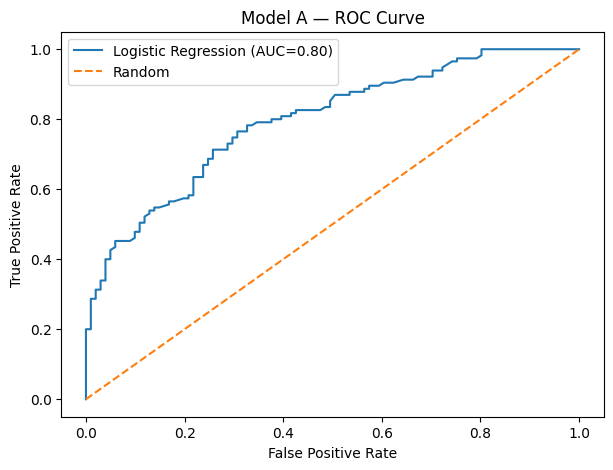

  ✔ Plot saved → eda_output_plots/model_a_confusion_matrix.png


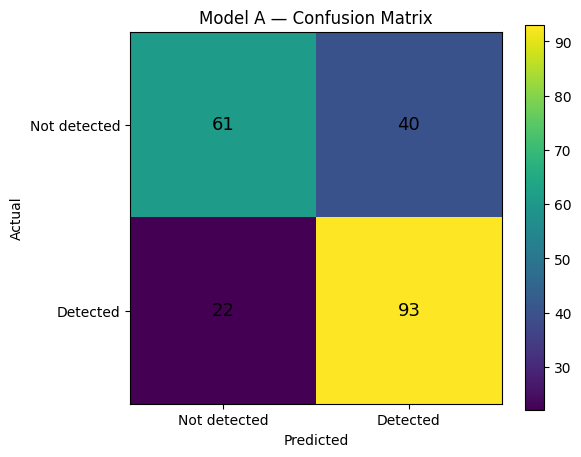


Feature importance:
        feature  importance    std
TRAMP_FARM_NAME      0.1073 0.0250
      SITE_NAME      0.0859 0.0129
           UNIT      0.0341 0.0145
    DESCRIPTION      0.0191 0.0121
      MONTH_SIN      0.0060 0.0036
      MONTH_COS     -0.0030 0.0039
  ✔ Plot saved → eda_output_plots/model_a_importance.png


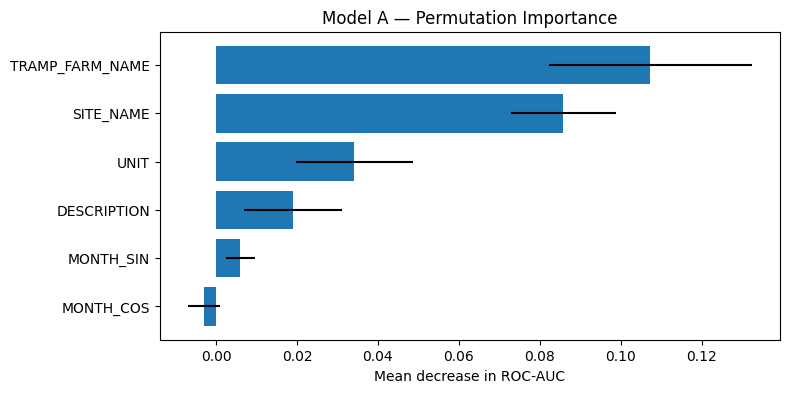


  MODEL B — EXPECTED CONCENTRATION IF DETECTED
  ✔ Real detected measurements: 2,313
  ✔ Train: 1,856 | Test: 457
  ✔ Split grouped by laboratory sample

  MODEL B COMPARISON — 5-FOLD CV
  ✔ Baseline (mean)          R²=-0.003 | MAE=1.710 | RMSE=1.815
  ✔ Random Forest            R²=0.956 | MAE=0.191 | RMSE=0.377
  ✔ Extra Trees              R²=0.950 | MAE=0.193 | RMSE=0.400
  ✔ Hist Gradient Boosting   R²=0.867 | MAE=0.356 | RMSE=0.654

  MODEL B — TEST SET PERFORMANCE
  ★ Selected model       : Random Forest
  R² (log scale)         : 0.914
  MAE (log scale)        : 0.224
  RMSE (log scale)       : 0.534
  MAE (original units)   : 5.889
  RMSE (original units)  : 20.843
  ✔ Plot saved → eda_output_plots/model_b_actual_vs_predicted.png


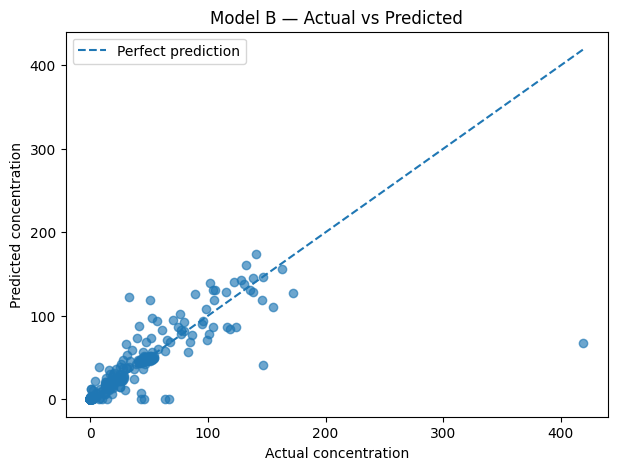

  ✔ Complete model bundle saved → model_output/contamination_model.joblib

  READY
Example prediction:
{
  "site": "Aldermaston",
  "sample_type": "APE - Apple",
  "month": 7,
  "detection_probability": 0.5532,
  "detection_likelihood": "MEDIUM",
  "model_classification": "DETECTED",
  "decision_threshold": 0.435,
  "meaning": "Likelihood that a man-made radionuclide is detected; this is not a safety verdict."
}

Generated files:
  • contamination_dataset.csv
  • model_output/contamination_model.joblib
  • model_output/contamination_metrics.json
  • model_output/model_a_comparison.csv
  • model_output/model_a_importance.csv
  • model_output/model_b_comparison.csv
  • eda_output_plots/


In [ ]:
"""
RADIONUCLIDE MONITORING — CONTAMINATION PROXY PREDICTION MODELS
Version: 2.1

Important:
- The source data does not contain a water-safety label and contains many
  non-water sample types.
- "Contamination" is only a transparent proxy:
  a man-made radionuclide was detected in a laboratory sample.
- Detection does NOT mean unsafe. This model estimates detection likelihood.
- Model A predicts detection likelihood at sample level.
- Model B predicts expected measured concentration for a selected nuclide,
  conditional on that nuclide being detected.
"""

from __future__ import annotations

import glob
import json
import os
import warnings
from pathlib import Path
from typing import Optional

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.ensemble import (
    ExtraTreesClassifier,
    ExtraTreesRegressor,
    HistGradientBoostingClassifier,
    HistGradientBoostingRegressor,
    RandomForestClassifier,
    RandomForestRegressor,
)
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    precision_score,
    r2_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import (
    GroupShuffleSplit,
    StratifiedKFold,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")

# ============================================================================
# CONFIG
# ============================================================================

FILE_PATH = (
    "/content/provisional-2016-bi-annual-aquatic-and-terrestrial-"
    "monitoring-results-26062017-raw-results.csv"
)

SEARCH_KEYWORDS = ["monitoring", "aquatic", "terrestrial", "provisional"]

TARGET_COL = "RESULT_NO_FLAG_UnitsAmendedForRIFE-AllBq's"
DATE_COL = "DATE_COLLECTED"
SAMPLE_ID_COL = "LABORATORY_SAMPLE_NUMBER"

NATURAL_OR_BACKGROUND = {
    "K-40", "C-14", "C-14(N)", "H-3", "OBT", "S-35", "BE-7",
    "PO-210", "PB-210", "RA-226", "RA-228", "TH-228", "TH-230",
    "TH-232", "U-234", "U-235", "U-238", "TOTAL BETA", "TOTAL ALPHA",
}

HIGH_THRESHOLD = 0.65
LOW_THRESHOLD = 0.35

CV_FOLDS = 5
TEST_SIZE = 0.20
RANDOM_STATE = 42

OUTPUT_DIR = Path("eda_output_plots")
MODEL_DIR = Path("model_output")
DATASET_FILENAME = "contamination_dataset.csv"

SAVE_DATASET = True
SHOW_PLOTS = True

# Ensure both required directories are created before any other code runs
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# ============================================================================
# HELPERS
# ============================================================================

def banner(title: str) -> None:
    print("\n" + "=" * 72)
    print(f"  {title}")
    print("=" * 72)


def save_plot(fig: plt.Figure, filename: str) -> None:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    path = OUTPUT_DIR / filename
    fig.savefig(path, dpi=160, bbox_inches="tight")
    print(f"  ✔ Plot saved → {path}")
    if SHOW_PLOTS:
        plt.show()
    plt.close(fig)


def safe_mode(series: pd.Series, default: str = "missing") -> str:
    series = series.dropna().astype(str).str.strip()
    if series.empty:
        return default
    modes = series.mode()
    return str(modes.iloc[0]) if not modes.empty else default


def month_features(month: int) -> tuple[float, float]:
    if not 1 <= int(month) <= 12:
        raise ValueError("month must be between 1 and 12")
    angle = 2 * np.pi * int(month) / 12.0
    return float(np.sin(angle)), float(np.cos(angle))


def make_preprocessor(
    categorical_columns: list[str],
    numeric_columns: list[str],
    scale_numeric: bool = False,
) -> ColumnTransformer:
    numeric_steps = [("imputer", SimpleImputer(strategy="median"))]

    if scale_numeric:
        numeric_steps.append(("scaler", StandardScaler()))

    return ColumnTransformer(
        transformers=[
            ("num", Pipeline(numeric_steps), numeric_columns),
            (
                "cat",
                Pipeline([
                    ("imputer", SimpleImputer(strategy="most_frequent")),
                    (
                        "onehot",
                        OneHotEncoder(
                            handle_unknown="ignore",
                            sparse_output=False,
                            min_frequency=3,
                        ),
                    ),
                ]),
                categorical_columns,
            ),
        ],
        remainder="drop",
    )


def save_json(data: dict, filename: str) -> None:
    MODEL_DIR.mkdir(parents=True, exist_ok=True)
    with open(MODEL_DIR / filename, "w", encoding="utf-8") as f:
        json.dump(data, f, indent=2)

# ============================================================================
# 1. LOAD AND VALIDATE
# ============================================================================

def find_dataset(path: str) -> str:
    if os.path.isfile(path):
        return path

    print(f"  ⚠ {path} not found. Searching for the monitoring dataset...")

    candidates = []
    for pattern in ("*.csv", "**/*.csv"):
        candidates.extend(glob.glob(pattern, recursive=True))
        candidates.extend(glob.glob(f"/content/{pattern}", recursive=True))

    candidates = sorted(set(candidates))

    for candidate in candidates:
        name = os.path.basename(candidate).lower()
        if all(k in name for k in SEARCH_KEYWORDS[:1]):
            print(f"  ✔ Found dataset at: {candidate}")
            return candidate

    for candidate in candidates:
        name = candidate.lower()
        if any(k in name for k in SEARCH_KEYWORDS):
            print(f"  ✔ Found dataset at: {candidate}")
            return candidate

    raise FileNotFoundError(
        "Raw CSV not found. Upload it to Colab or update FILE_PATH."
    )


def load_raw(path: str) -> pd.DataFrame:
    df = pd.read_csv(path, low_memory=False)

    before = len(df)
    df = df.drop_duplicates().reset_index(drop=True)
    duplicates_removed = before - len(df)

    required = [
        TARGET_COL,
        "LOD",
        "NAME",
        "SITE_NAME",
        "DESCRIPTION",
        "UNIT",
        "TRAMP_FARM_NAME",
        DATE_COL,
        SAMPLE_ID_COL,
    ]

    missing = [column for column in required if column not in df.columns]
    if missing:
        raise KeyError(f"Missing columns in the CSV: {missing}")

    df[TARGET_COL] = pd.to_numeric(df[TARGET_COL], errors="coerce")

    text_columns = [
        "LOD",
        "NAME",
        "SITE_NAME",
        "DESCRIPTION",
        "UNIT",
        "TRAMP_FARM_NAME",
        SAMPLE_ID_COL,
    ]

    for column in text_columns:
        df[column] = df[column].fillna("").astype(str).str.strip()

    df["NAME"] = df["NAME"].str.upper()

    lod = df["LOD"]
    df["DETECTED"] = np.where(
        lod.eq(""),
        np.nan,
        (~lod.str.contains("<", regex=False)).astype(float),
    )

    dates = pd.to_datetime(df[DATE_COL], errors="coerce", dayfirst=True)
    df["MONTH"] = dates.dt.month

    print(f"  ✔ Loaded {len(df):,} rows × {df.shape[1]:,} columns")
    print(f"  ✔ Duplicate rows removed: {duplicates_removed:,}")
    print(f"  ✔ Unknown LOD rows: {df['DETECTED'].isna().sum():,}")
    print(f"  ✔ Date parsing failures: {dates.isna().sum():,}")

    return df

# ============================================================================
# 2. BUILD MODEL-A SAMPLE DATASET
# ============================================================================

CAT_A = ["SITE_NAME", "TRAMP_FARM_NAME", "DESCRIPTION", "UNIT"]
NUM_A = ["MONTH_SIN", "MONTH_COS"]

CAT_B = ["SITE_NAME", "TRAMP_FARM_NAME", "DESCRIPTION", "UNIT", "NAME"]
NUM_B = ["MONTH_SIN", "MONTH_COS"]


def add_month_features(df: pd.DataFrame) -> pd.DataFrame:
    result = df.copy()

    month = pd.to_numeric(result["MONTH"], errors="coerce")
    result["MONTH_SIN"] = np.sin(2 * np.pi * month / 12.0)
    result["MONTH_COS"] = np.cos(2 * np.pi * month / 12.0)

    return result


def build_sample_table(df: pd.DataFrame) -> pd.DataFrame:
    artificial = df[
        (~df["NAME"].isin(NATURAL_OR_BACKGROUND))
        & df["DETECTED"].notna()
    ].copy()

    if artificial.empty:
        raise ValueError(
            "No usable man-made radionuclide records were found after filtering."
        )

    sample = (
        artificial.groupby(SAMPLE_ID_COL, dropna=False)
        .agg(
            CONTAMINATION_DETECTED=("DETECTED", "max"),
            N_ARTIFICIAL_TESTS=("DETECTED", "size"),
            N_ARTIFICIAL_DETECTED=("DETECTED", "sum"),
            SITE_NAME=("SITE_NAME", "first"),
            TRAMP_FARM_NAME=("TRAMP_FARM_NAME", "first"),
            DESCRIPTION=("DESCRIPTION", "first"),
            UNIT=("UNIT", "first"),
            MONTH=("MONTH", "first"),
        )
        .reset_index()
    )

    sample["CONTAMINATION_DETECTED"] = (
        sample["CONTAMINATION_DETECTED"].astype(int)
    )
    sample["N_ARTIFICIAL_DETECTED"] = (
        sample["N_ARTIFICIAL_DETECTED"].astype(int)
    )

    sample = add_month_features(sample)

    positive_rate = sample["CONTAMINATION_DETECTED"].mean() * 100

    print(
        f"  ✔ Sample table: {len(sample):,} samples | "
        f"{positive_rate:.1f}% have a man-made nuclide detected"
    )

    return sample

# ============================================================================
# 3. MODEL A — DETECTION CLASSIFIER
# ============================================================================

def model_a_candidates() -> dict:
    return {
        "Baseline (prior)": (
            DummyClassifier(strategy="prior"),
            False,
        ),
        "Logistic Regression": (
            LogisticRegression(
                C=0.5,
                max_iter=3000,
                class_weight="balanced",
                random_state=RANDOM_STATE,
            ),
            True,
        ),
        "Random Forest": (
            RandomForestClassifier(
                n_estimators=500,
                min_samples_leaf=3,
                class_weight="balanced",
                n_jobs=-1,
                random_state=RANDOM_STATE,
            ),
            False,
        ),
        "Extra Trees": (
            ExtraTreesClassifier(
                n_estimators=500,
                min_samples_leaf=2,
                class_weight="balanced",
                n_jobs=-1,
                random_state=RANDOM_STATE,
            ),
            False,
        ),
        "Hist Gradient Boosting": (
            HistGradientBoostingClassifier(
                learning_rate=0.05,
                max_iter=250,
                max_leaf_nodes=31,
                l2_regularization=1.0,
                random_state=RANDOM_STATE,
            ),
            False,
        ),
    }


def find_best_threshold(y_true: pd.Series, probability: np.ndarray) -> float:
    thresholds = np.linspace(0.10, 0.90, 161)

    best_threshold = 0.50
    best_score = -1.0

    for threshold in thresholds:
        prediction = (probability >= threshold).astype(int)
        score = f1_score(y_true, prediction, zero_division=0)

        if score > best_score:
            best_score = score
            best_threshold = float(threshold)

    return best_threshold


def train_model_a(samples: pd.DataFrame) -> dict:
    banner("MODEL A — MAN-MADE RADIONUCLIDE DETECTION")

    X = samples[CAT_A + NUM_A].copy()
    y = samples["CONTAMINATION_DETECTED"].astype(int)

    if y.nunique() < 2:
        raise ValueError("Model A requires both detected and not-detected samples.")

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=TEST_SIZE,
        stratify=y,
        random_state=RANDOM_STATE,
    )

    print(
        f"  ✔ Train: {len(X_train):,} | "
        f"Test: {len(X_test):,}"
    )

    cv = StratifiedKFold(
        n_splits=CV_FOLDS,
        shuffle=True,
        random_state=RANDOM_STATE,
    )

    scoring = {
        "roc_auc": "roc_auc",
        "pr_auc": "average_precision",
        "balanced_accuracy": "balanced_accuracy",
        "f1": "f1",
    }

    rows = []
    pipelines = {}

    banner(f"MODEL COMPARISON — {CV_FOLDS}-FOLD CV")

    for name, (model, scale) in model_a_candidates().items():
        pipe = Pipeline([
            ("prep", make_preprocessor(CAT_A, NUM_A, scale)),
            ("model", model),
        ])

        scores = cross_validate(
            pipe,
            X_train,
            y_train,
            cv=cv,
            scoring=scoring,
            n_jobs=1,
        )

        row = {
            "model": name,
            "cv_roc_auc": scores["test_roc_auc"].mean(),
            "cv_pr_auc": scores["test_pr_auc"].mean(),
            "cv_balanced_accuracy": scores["test_balanced_accuracy"].mean(),
            "cv_f1": scores["test_f1"].mean(),
            "cv_roc_auc_std": scores["test_roc_auc"].std(),
        }

        rows.append(row)
        pipelines[name] = pipe

        print(
            f"  ✔ {name:<24} "
            f"ROC-AUC={row['cv_roc_auc']:.3f} | "
            f"PR-AUC={row['cv_pr_auc']:.3f} | "
            f"BalAcc={row['cv_balanced_accuracy']:.3f} | "
            f"F1={row['cv_f1']:.3f}"
        )

    comparison = (
        pd.DataFrame(rows)
        .sort_values(
            ["cv_pr_auc", "cv_roc_auc", "cv_f1"],
            ascending=False,
        )
        .reset_index(drop=True)
    )

    print("\n" + comparison.to_string(index=False, float_format="{:.3f}".format))

    best_name = comparison.loc[0, "model"]

    base_pipeline = clone(pipelines[best_name])

    calibrated = CalibratedClassifierCV(
        estimator=base_pipeline,
        method="sigmoid",
        cv=CV_FOLDS,
    )

    calibrated.fit(X_train, y_train)

    threshold_pipe = clone(pipelines[best_name])
    oof_probability = np.zeros(len(X_train))

    for train_idx, valid_idx in cv.split(X_train, y_train):
        fold_model = clone(threshold_pipe)
        fold_model.fit(
            X_train.iloc[train_idx],
            y_train.iloc[train_idx],
        )
        oof_probability[valid_idx] = fold_model.predict_proba(
            X_train.iloc[valid_idx]
        )[:, 1]

    optimal_threshold = find_best_threshold(
        y_train,
        oof_probability,
    )

    probability = calibrated.predict_proba(X_test)[:, 1]
    prediction = (probability >= optimal_threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        prediction,
        labels=[0, 1],
    ).ravel()

    metrics = {
        "roc_auc": float(roc_auc_score(y_test, probability)),
        "pr_auc": float(average_precision_score(y_test, probability)),
        "balanced_accuracy": float(
            balanced_accuracy_score(y_test, prediction)
        ),
        "f1": float(f1_score(y_test, prediction, zero_division=0)),
        "precision": float(
            precision_score(y_test, prediction, zero_division=0)
        ),
        "recall": float(
            recall_score(y_test, prediction, zero_division=0)
        ),
        "positive_rate_test": float(y_test.mean()),
        "decision_threshold": float(optimal_threshold),
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp),
    }

    banner("MODEL A — TEST SET PERFORMANCE")

    print(f"  ★ Selected model      : {best_name}")
    print(f"  ROC-AUC               : {metrics['roc_auc']:.3f}")
    print(f"  PR-AUC                : {metrics['pr_auc']:.3f}")
    print(f"  Balanced accuracy     : {metrics['balanced_accuracy']:.3f}")
    print(f"  F1                    : {metrics['f1']:.3f}")
    print(f"  Precision             : {metrics['precision']:.3f}")
    print(f"  Recall                : {metrics['recall']:.3f}")
    print(f"  Decision threshold    : {optimal_threshold:.3f}")
    print(
        f"  Confusion matrix      : "
        f"TN={tn} FP={fp} FN={fn} TP={tp}"
    )

    fpr, tpr, _ = roc_curve(y_test, probability)

    fig, ax = plt.subplots(figsize=(7, 5))
    ax.plot(
        fpr,
        tpr,
        label=f"{best_name} (AUC={metrics['roc_auc']:.2f})",
    )
    ax.plot([0, 1], [0, 1], "--", label="Random")
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.set_title("Model A — ROC Curve")
    ax.legend()
    save_plot(fig, "model_a_roc_curve.png")

    cm = np.array([[tn, fp], [fn, tp]])

    fig, ax = plt.subplots(figsize=(6, 5))
    image = ax.imshow(cm)
    fig.colorbar(image, ax=ax)
    ax.set_xticks([0, 1], ["Not detected", "Detected"])
    ax.set_yticks([0, 1], ["Not detected", "Detected"])
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_title("Model A — Confusion Matrix")

    for (row, col), value in np.ndenumerate(cm):
        ax.text(
            col,
            row,
            str(value),
            ha="center",
            va="center",
            fontsize=13,
        )

    save_plot(fig, "model_a_confusion_matrix.png")

    importance = permutation_importance(
        calibrated,
        X_test,
        y_test,
        scoring="roc_auc",
        n_repeats=10,
        random_state=RANDOM_STATE,
        n_jobs=1,
    )

    importance_df = (
        pd.DataFrame({
            "feature": X_test.columns,
            "importance": importance.importances_mean,
            "std": importance.importances_std,
        })
        .sort_values("importance", ascending=False)
        .reset_index(drop=True)
    )

    print("\nFeature importance:")
    print(
        importance_df.to_string(
            index=False,
            float_format="{:.4f}".format,
        )
    )

    top = importance_df.sort_values("importance")

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.barh(
        top["feature"],
        top["importance"],
        xerr=top["std"],
    )
    ax.set_xlabel("Mean decrease in ROC-AUC")
    ax.set_title("Model A — Permutation Importance")
    save_plot(fig, "model_a_importance.png")

    MODEL_DIR.mkdir(parents=True, exist_ok=True)
    comparison.to_csv(
        MODEL_DIR / "model_a_comparison.csv",
        index=False,
    )

    importance_df.to_csv(
        MODEL_DIR / "model_a_importance.csv",
        index=False,
    )

    return {
        "pipeline": calibrated,
        "name": best_name,
        "threshold": optimal_threshold,
        "metrics": metrics,
    }

# ============================================================================
# 4. MODEL B — CONCENTRATION REGRESSION
# ============================================================================

def model_b_candidates() -> dict:
    return {
        "Baseline (mean)": DummyRegressor(strategy="mean"),
        "Random Forest": RandomForestRegressor(
            n_estimators=500,
            min_samples_leaf=2,
            n_jobs=-1,
            random_state=RANDOM_STATE,
        ),
        "Extra Trees": ExtraTreesRegressor(
            n_estimators=500,
            min_samples_leaf=2,
            n_jobs=-1,
            random_state=RANDOM_STATE,
        ),
        "Hist Gradient Boosting": HistGradientBoostingRegressor(
            learning_rate=0.05,
            max_iter=250,
            max_leaf_nodes=31,
            l2_regularization=1.0,
            random_state=RANDOM_STATE,
        ),
    }


def train_model_b(df: pd.DataFrame) -> dict:
    banner("MODEL B — EXPECTED CONCENTRATION IF DETECTED")

    data = df[
        (df["DETECTED"] == 1)
        & df[TARGET_COL].notna()
        & (df[TARGET_COL] >= 0)
    ].copy()

    data = add_month_features(data)

    if len(data) < 20:
        raise ValueError(
            "Too few detected measurements for a reliable regression model."
        )

    data["LOG_RESULT"] = np.log1p(data[TARGET_COL])

    X = data[CAT_B + NUM_B].copy()
    y = data["LOG_RESULT"].astype(float)

    groups = data[SAMPLE_ID_COL].astype(str).to_numpy()

    splitter = GroupShuffleSplit(
        n_splits=1,
        test_size=TEST_SIZE,
        random_state=RANDOM_STATE,
    )

    train_idx, test_idx = next(splitter.split(X, y, groups))

    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]
    y_train = y.iloc[train_idx]
    y_test = y.iloc[test_idx]

    print(
        f"  ✔ Real detected measurements: {len(data):,}\n"
        f"  ✔ Train: {len(X_train):,} | Test: {len(X_test):,}\n"
        f"  ✔ Split grouped by laboratory sample"
    )

    rows = []
    pipelines = {}

    from sklearn.model_selection import KFold

    cv = KFold(
        n_splits=CV_FOLDS,
        shuffle=True,
        random_state=RANDOM_STATE,
    )

    banner(f"MODEL B COMPARISON — {CV_FOLDS}-FOLD CV")

    for name, model in model_b_candidates().items():
        pipe = Pipeline([
            ("prep", make_preprocessor(CAT_B, NUM_B)),
            ("model", model),
        ])

        scores = cross_validate(
            pipe,
            X_train,
            y_train,
            cv=cv,
            scoring={
                "r2": "r2",
                "mae": "neg_mean_absolute_error",
                "rmse": "neg_root_mean_squared_error",
            },
            n_jobs=1,
        )

        row = {
            "model": name,
            "cv_r2_log": scores["test_r2"].mean(),
            "cv_mae_log": -scores["test_mae"].mean(),
            "cv_rmse_log": -scores["test_rmse"].mean(),
        }

        rows.append(row)
        pipelines[name] = pipe

        print(
            f"  ✔ {name:<24} "
            f"R²={row['cv_r2_log']:.3f} | "
            f"MAE={row['cv_mae_log']:.3f} | "
            f"RMSE={row['cv_rmse_log']:.3f}"
        )

    comparison = (
        pd.DataFrame(rows)
        .sort_values(
            ["cv_r2_log", "cv_mae_log"],
            ascending=[False, True],
        )
        .reset_index(drop=True)
    )

    best_name = comparison.loc[0, "model"]
    best = clone(pipelines[best_name])
    best.fit(X_train, y_train)

    prediction_log = best.predict(X_test)
    baseline = DummyRegressor(strategy="mean").fit(X_train, y_train)
    baseline_log = baseline.predict(X_test)

    actual = np.expm1(y_test.to_numpy())
    predicted = np.maximum(0, np.expm1(prediction_log))
    baseline_original = np.maximum(0, np.expm1(baseline_log))

    metrics = {
        "r2_log": float(r2_score(y_test, prediction_log)),
        "mae_log": float(mean_absolute_error(y_test, prediction_log)),
        "rmse_log": float(
            np.sqrt(mean_squared_error(y_test, prediction_log))
        ),
        "baseline_r2_log": float(r2_score(y_test, baseline_log)),
        "mae_original_units": float(
            mean_absolute_error(actual, predicted)
        ),
        "rmse_original_units": float(
            np.sqrt(mean_squared_error(actual, predicted))
        ),
        "baseline_mae_original_units": float(
            mean_absolute_error(actual, baseline_original)
        ),
    }

    banner("MODEL B — TEST SET PERFORMANCE")

    print(f"  ★ Selected model       : {best_name}")
    print(f"  R² (log scale)         : {metrics['r2_log']:.3f}")
    print(f"  MAE (log scale)        : {metrics['mae_log']:.3f}")
    print(f"  RMSE (log scale)       : {metrics['rmse_log']:.3f}")
    print(
        f"  MAE (original units)   : "
        f"{metrics['mae_original_units']:.3f}"
    )
    print(
        f"  RMSE (original units)  : "
        f"{metrics['rmse_original_units']:.3f}"
    )

    fig, ax = plt.subplots(figsize=(7, 5))
    ax.scatter(actual, predicted, alpha=0.65)

    limit = max(
        float(np.max(actual)) if len(actual) else 1,
        float(np.max(predicted)) if len(predicted) else 1,
    )

    ax.plot([0, limit], [0, limit], "--", label="Perfect prediction")
    ax.set_xlabel("Actual concentration")
    ax.set_ylabel("Predicted concentration")
    ax.set_title("Model B — Actual vs Predicted")
    ax.legend()
    save_plot(fig, "model_b_actual_vs_predicted.png")

    MODEL_DIR.mkdir(parents=True, exist_ok=True)
    comparison.to_csv(
        MODEL_DIR / "model_b_comparison.csv",
        index=False,
    )

    return {
        "pipeline": best,
        "name": best_name,
        "metrics": metrics,
    }

# ============================================================================
# 5. SAVE DATASET AND MODEL BUNDLES
# ============================================================================

def build_default_maps(df: pd.DataFrame) -> dict:
    unit_by_desc = (
        df.groupby("DESCRIPTION")["UNIT"]
        .apply(safe_mode)
        .to_dict()
    )

    farm_by_site_desc = (
        df.groupby(["SITE_NAME", "DESCRIPTION"])["TRAMP_FARM_NAME"]
        .apply(safe_mode)
        .to_dict()
    )

    farm_by_desc = (
        df.groupby("DESCRIPTION")["TRAMP_FARM_NAME"]
        .apply(safe_mode)
        .to_dict()
    )

    return {
        "unit_by_desc": unit_by_desc,
        "farm_by_site_desc": farm_by_site_desc,
        "farm_by_desc": farm_by_desc,
    }


def train_all(df: pd.DataFrame) -> dict:
    samples = build_sample_table(df)

    if SAVE_DATASET:
        output = samples.drop(
            columns=["MONTH"],
            errors="ignore",
        )

        output_path = Path(DATASET_FILENAME)
        output.to_csv(output_path, index=False)

        print(
            f"  ✔ Dataset saved → {output_path.resolve()} "
            f"({len(output):,} rows × {output.shape[1]} columns)"
        )

        try:
            from google.colab import files
            files.download(str(output_path))
        except ImportError:
            pass

    model_a = train_model_a(samples)
    model_b = train_model_b(df)

    maps = build_default_maps(df)

    bundle = {
        "version": "2.0",
        "model_a": model_a["pipeline"],
        "model_b": model_b["pipeline"],
        "model_a_name": model_a["name"],
        "model_b_name": model_b["name"],
        "model_a_threshold": model_a["threshold"],
        "options": {
            "sites": sorted(df["SITE_NAME"].dropna().unique().tolist()),
            "sample_types": sorted(
                df["DESCRIPTION"].dropna().unique().tolist()
            ),
            "nuclides": sorted(
                df["NAME"].dropna().unique().tolist()
            ),
        },
        **maps,
    }

    MODEL_DIR.mkdir(parents=True, exist_ok=True)

    model_path = MODEL_DIR / "contamination_model.joblib"
    joblib.dump(bundle, model_path)

    metrics = {
        "version": "2.0",
        "model_a": model_a["name"],
        "model_a_test": model_a["metrics"],
        "model_b": model_b["name"],
        "model_b_test": model_b["metrics"],
    }

    save_json(metrics, "contamination_metrics.json")

    print(f"  ✔ Complete model bundle saved → {model_path}")

    return bundle

# ============================================================================
# 6. PREDICTION API
# ============================================================================

def list_options(
    model_path: str = str(MODEL_DIR / "contamination_model.joblib"),
) -> dict:
    bundle = joblib.load(model_path)
    return bundle["options"]


def predict_contamination(
    site: str,
    sample_type: str,
    month: int,
    nuclide: Optional[str] = None,
    farm: Optional[str] = None,
    unit: Optional[str] = None,
    model_path: str = str(MODEL_DIR / "contamination_model.joblib"),
) -> dict:
    bundle = joblib.load(model_path)
    options = bundle["options"]

    site = str(site).strip()
    sample_type = str(sample_type).strip()

    if not 1 <= int(month) <= 12:
        raise ValueError("month must be between 1 and 12")

    notes = []

    if site not in options["sites"]:
        notes.append(
            f"Site '{site}' was not in the training data."
        )

    if sample_type not in options["sample_types"]:
        notes.append(
            f"Sample type '{sample_type}' was not in the training data."
        )

    unit = unit or bundle["unit_by_desc"].get(
        sample_type,
        "missing",
    )

    farm = farm or bundle["farm_by_site_desc"].get(
        (site, sample_type),
        bundle["farm_by_desc"].get(sample_type, "missing"),
    )

    month_sin, month_cos = month_features(month)

    model_a_input = pd.DataFrame([{
        "SITE_NAME": site,
        "TRAMP_FARM_NAME": farm,
        "DESCRIPTION": sample_type,
        "UNIT": unit,
        "MONTH_SIN": month_sin,
        "MONTH_COS": month_cos,
    }])

    probability = float(
        bundle["model_a"].predict_proba(model_a_input)[0, 1]
    )

    decision_threshold = float(bundle["model_a_threshold"])

    likelihood = (
        "HIGH"
        if probability >= HIGH_THRESHOLD
        else "LOW"
        if probability < LOW_THRESHOLD
        else "MEDIUM"
    )

    classified_detection = int(
        probability >= decision_threshold
    )

    result = {
        "site": site,
        "sample_type": sample_type,
        "month": int(month),
        "detection_probability": round(probability, 4),
        "detection_likelihood": likelihood,
        "model_classification": (
            "DETECTED" if classified_detection else "NOT_DETECTED"
        ),
        "decision_threshold": round(decision_threshold, 4),
        "meaning": (
            "Likelihood that a man-made radionuclide is detected; "
            "this is not a safety verdict."
        ),
    }

    if nuclide:
        nuclide = str(nuclide).upper().strip()

        if nuclide not in options["nuclides"]:
            notes.append(
                f"Nuclide '{nuclide}' was not in the training data."
            )

        model_b_input = pd.DataFrame([{
            "SITE_NAME": site,
            "TRAMP_FARM_NAME": farm,
            "DESCRIPTION": sample_type,
            "UNIT": unit,
            "NAME": nuclide,
            "MONTH_SIN": month_sin,
            "MONTH_COS": month_cos,
        }])

        predicted_log = float(
            bundle["model_b"].predict(model_b_input)[0]
        )

        predicted_value = max(0.0, float(np.expm1(predicted_log)))

        result["nuclide"] = nuclide
        result["expected_result_if_detected"] = (
            f"{predicted_value:.4g} {unit}"
        )

    if notes:
        result["warnings"] = notes

    return result

# ============================================================================
# 7. MAIN
# ============================================================================

def main() -> None:
    banner("RADIONUCLIDE MONITORING MODEL — START")

    raw_path = find_dataset(FILE_PATH)
    raw = load_raw(raw_path)

    bundle = train_all(raw)

    banner("READY")

    site = bundle["options"]["sites"][0]
    sample_type = bundle["options"]["sample_types"][0]

    example = predict_contamination(
        site=site,
        sample_type=sample_type,
        month=7,
    )

    print("Example prediction:")
    print(json.dumps(example, indent=2))

    print("\nGenerated files:")
    print(f"  • {DATASET_FILENAME}")
    print(f"  • {MODEL_DIR / 'contamination_model.joblib'}")
    print(f"  • {MODEL_DIR / 'contamination_metrics.json'}")
    print(f"  • {MODEL_DIR / 'model_a_comparison.csv'}")
    print(f"  • {MODEL_DIR / 'model_a_importance.csv'}")
    print(f"  • {MODEL_DIR / 'model_b_comparison.csv'}")
    print(f"  • {OUTPUT_DIR}/")


if __name__ == "__main__":
    main()

In [ ]:
pip install shap


In [ ]:
!pip install streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.3/10.3 MB 25.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 28.6 MB/s eta 0:00:00


In [ ]:
# ===========================================================
# AquaPredict v7.0 "Ripple" - dark underwater UI, interactive water background
#
# RUN: Terminal -> streamlit run app_ripple.py (streamlit >= 1.40)
# Colab -> use the cells in colab_launcher.py (point it at this file)
#
# SAME BACKEND / FEATURES AS v6 (nothing removed):
# * classification + regression, nuclide-aware classifier, caching
# * risk gauge ring, seasonal wheel, site-risk donut, key-factor donut,
# percentile ring, concentration wheel, bar/trend/baseline charts
# * rule-based insights, recommendations, 12-month tables, CSV downloads
# * confusion matrix + accuracy/precision/recall/F1, feature importance
#
# NEW UI: ripple/bubble/light-shaft canvas background that reacts to the mouse
# (move = ripples, click = big ripple, bubbles flee the cursor), outlined
# wave-letter hero, cursor spotlight on cards, dark glass theme.
#
# SETUP NOTES (unchanged)
# 1. No "%%writefile" line inside this file (Colab-only magic).
# 2. Confusion matrix: save bundle["confusion_matrix"] (2x2) after training,
# or bundle["metrics"]["confusion_matrix"]. Models from
# improve_and_save_metrics.py need aqua_features.py next to the app.
# 3. Feature importance: bundle["feature_importance"] = {"Site": 0.4, ...}
# 4. Nuclide-aware classifier: run improve_and_save_metrics.py once.
# 5. Results column auto-detected; force it with RESULT_COL_OVERRIDE below.
# ===========================================================

# ---- USER CONFIG -------------------------------------------
RESULT_COL_OVERRIDE = None # e.g. "RESULT_NO_FLAG_UnitsAmendedForRIFE-AllBq's"
# ------------------------------------------------------------

import base64
import html
import io
import math
import os
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import streamlit as st
import streamlit.components.v1 as components

try:
    import aqua_features # noqa: F401
except ImportError:
    pass

# -----------------------------------------------------------
# Execution guard
# -----------------------------------------------------------
try:
    from streamlit.runtime.scriptrunner import get_script_run_ctx
    _CTX = get_script_run_ctx() is not None
except Exception:
    _CTX = False

if not _CTX:
    print("AquaPredict is a Streamlit app, not a normal script.\n"
          "Terminal: streamlit run app_ripple.py\nColab: run the cells in colab_launcher.py")
    raise SystemExit

st.set_page_config(page_title="AquaPredict · Radioactivity forecasts", page_icon="💧", layout="wide", initial_sidebar_state="collapsed")

MONTHS = ["January", "February", "March", "April", "May", "June", "July", "August", "September", "October", "November", "December"]
SHORT_MONTHS = [m[:3] for m in MONTHS]
LVL_COL = {"LOW": "#34D399", "MEDIUM": "#FBBF24", "HIGH": "#F87171"}
ACC, ACC2 = "#7DD3FC", "#5EEAD4"

def md(s: str):
    st.markdown(" ".join(l.strip() for l in s.strip().splitlines() if l.strip()), unsafe_allow_html=True)

def esc(x) -> str:
    return html.escape(str(x))

def html_table(df):
    head = "".join(f"<th>{esc(c)}</th>" for c in df.columns)
    body = "".join("<tr>" + "".join(f"<td>{esc(v)}</td>" for v in r) + "</tr>" for r in df.itertuples(index=False))
    md(f'<div class="tbl-wrap"><table class="tbl"><thead><tr>{head}</tr></thead><tbody>{body}</tbody></table></div>')

# -----------------------------------------------------------
# Images (optional decoration)
# -----------------------------------------------------------
IMAGE_EXTS = {".png", ".jpg", ".jpeg", ".webp", ".gif"}
SKIP_DIRS = {"sample_data", "model_output", "__pycache__", "drive", "site-packages", "node_modules"}

@st.cache_data(show_spinner=False)
def list_images():
    found, seen = [], set()
    roots = {str(Path(r).resolve()) for r in ("/content", ".") if Path(r).exists()}
    for root in roots:
        base_depth = root.rstrip(os.sep).count(os.sep)
        for dp, dn, fn in os.walk(root):
            dn[:] = [d for d in dn if d not in SKIP_DIRS and not d.startswith(".")]
            if dp.count(os.sep) - base_depth >= 3:
                dn[:] = []
            for f in fn:
                if Path(f).suffix.lower() in IMAGE_EXTS:
                    p = str(Path(dp, f).resolve())
                    if p not in seen:
                        seen.add(p)
                        found.append(p)
    return sorted(found)

@st.cache_data(show_spinner=False)
def image_data_uri(path, max_w=1400):
    if not path or not Path(path).exists():
        return ""
    try:
        from PIL import Image
        img = Image.open(path)
        if getattr(img, "is_animated", False):
            img.seek(0)
        if img.mode in ("RGBA", "LA", "P"):
            img = img.convert("RGBA")
            bg = Image.new("RGB", img.size, (0, 0, 0))
            bg.paste(img, mask=img.split()[-1])
            img = bg
        else:
            img = img.convert("RGB")
        if img.width > max_w:
            img = img.resize((max_w, int(img.height * max_w / img.width)))
        buf = io.BytesIO()
        img.save(buf, format="JPEG", quality=80)
        return "data:image/jpeg;base64," + base64.b64encode(buf.getvalue()).decode()
    except Exception:
        return ""

def _pick(imgs, used, keywords):
    best, score = None, 0
    for p in imgs:
        if p in used:
            continue
        s = sum(k in Path(p).name.lower() for k in keywords)
        if s > score:
            best, score = p, s
    return best

_imgs = list_images()
_used = set()
_main = _pick(_imgs, _used, ("contamination", "pollution", "river", "water", "scientist", "sample", "testing"))
if _main:
    _used.add(_main)
_lab = _pick(_imgs, _used, ("laboratory", "lab", "analysis", "sensor", "monitor"))

_rest = [p for p in _imgs if p not in (_main, _lab)]
_main = _main or (_rest.pop(0) if _rest else None)
_lab = _lab or (_rest.pop(0) if _rest else None) or _main
IMG_MAIN, IMG_LAB = image_data_uri(_main), image_data_uri(_lab)

def image_tag(src, alt):
    return f'<img class="img-fill" src="{src}" alt="{esc(alt)}" loading="lazy">' if src else ""

# -----------------------------------------------------------
# Model + data
# -----------------------------------------------------------
MODEL_CANDIDATES = [Path("/content/model_output/contamination_model.joblib"),
                    Path("model_output/contamination_model.joblib"),
                    Path("contamination_model.joblib")]
DATA_CANDIDATES = [Path("/content/contamination_dataset.csv"), Path("contamination_dataset.csv")]

@st.cache_resource
def load_bundle():
    for p in MODEL_CANDIDATES:
        if p.exists():
            return joblib.load(p)
    return None

bundle = load_bundle()
if bundle is None:
    st.error("Model file not found. Looked in: " + ", ".join(str(p) for p in MODEL_CANDIDATES))
    st.stop()

model_a, model_b = bundle["model_a"], bundle["model_b"]
USES_NUC = bool(bundle.get("model_a_uses_nuclide", False))
threshold = float(bundle["model_a_threshold"])
sites = list(bundle["options"]["sites"])
sample_types = list(bundle["options"]["sample_types"])
nuclides = list(bundle["options"]["nuclides"])
unit_by_desc = bundle["unit_by_desc"]
farm_by_site_desc = bundle["farm_by_site_desc"]
farm_by_desc = bundle["farm_by_desc"]
LO = min(0.35, threshold)
HI = max(0.65, threshold)

@st.cache_data(show_spinner=False)
def load_raw_data():
    paths = list(DATA_CANDIDATES) + sorted(Path("/content").glob("*.csv")) + sorted(Path(".").glob("*.csv"))
    for p in paths:
        try:
            if not Path(p).exists():
                continue
            head = pd.read_csv(p, nrows=5, low_memory=False)
            if all(c in head.columns for c in ["SITE_NAME", "DESCRIPTION", "NAME"]):
                return pd.read_csv(p, low_memory=False)
        except Exception:
            continue
    return None

raw_data = load_raw_data()

def detect_result_col(df):
    if df is None:
        return None
    if RESULT_COL_OVERRIDE and RESULT_COL_OVERRIDE in df.columns:
        return RESULT_COL_OVERRIDE
    preferred = "RESULT_NO_FLAG_UnitsAmendedForRIFE-AllBq's"
    if preferred in df.columns:
        return preferred
    best, best_score = None, 0.0
    for c in df.columns:
        name = str(c).lower()
        if "result" not in name or "flag" in name.replace("no_flag", ""):
            continue
        frac = pd.to_numeric(df[c], errors="coerce").notna().mean()
        score = frac + (0.2 if "bq" in name or "amended" in name else 0)
        if frac >= 0.3 and score > best_score:
            best, best_score = c, score
    return best

RESULT_COL = detect_result_col(raw_data)

# -----------------------------------------------------------
# State
# -----------------------------------------------------------
st.session_state.setdefault("service", "Will it be detected?")
st.session_state.setdefault("analysis_result", None)

def clear_result():
    st.session_state.analysis_result = None

def show_chart(fig):
    cfg = {"displayModeBar": False}
    try:
        st.plotly_chart(fig, use_container_width=True, config=cfg)
    except TypeError:
        st.plotly_chart(fig, width="stretch", config=cfg)

# -----------------------------------------------------------
# Theme (dark underwater)
# -----------------------------------------------------------
st.markdown(
"""
<style>
@import url('https://fonts.googleapis.com/css2?family=Fraunces:ital,opsz,wght@0,9..144,500;0,9..144,700;1,9..144,500;1,9..144,700&family=DM+Sans:wght@400;500;600;700&display=swap');
:root{--ink:#F2EFE9;--slate:#B9B6AF;--muted:#8A8780;--acc:#8FD3E8;--acc2:#5EEAD4;--line:rgba(255,255,255,.12);
--glass:rgba(12,12,12,.62);--r:24px;--r-sm:16px;--low:#34D399;--med:#FBBF24;--high:#F87171}
html{scroll-behavior:smooth}
html,body{background:#000!important}
html,body,.stApp,.stApp p,.stApp label,.stApp button,.stApp input,.stApp span{font-family:'DM Sans',sans-serif}
.stApp,[data-testid="stAppViewContainer"],[data-testid="stMain"],.main{background:transparent!important}
.stApp{color:var(--ink)}
[data-testid="stSidebar"],[data-testid="collapsedControl"],[data-testid="stHeader"],[data-testid="stToolbar"],[data-testid="stDecoration"],footer{display:none!important}
.block-container{max-width:1240px!important;padding:14px 24px 80px!important}
h1,h2,h3,h4{color:var(--ink);font-weight:700;letter-spacing:0}
h1,h2,h3,h4,.hero-title,.hero-title .ltr,.panel-title,.about-title,.nav-brand,.stat-value,.kpi b,.advisor-title{font-family:'Fraunces',Georgia,serif!important}
.stMarkdown p,.stMarkdown li{color:var(--slate);font-weight:500}
iframe[height="0"]{position:absolute;opacity:0;pointer-events:none;height:0}
.element-container:has(iframe[height="0"]),[data-testid="stElementContainer"]:has(iframe[height="0"]){height:0;margin:0;overflow:hidden}
::selection{background:rgba(125,211,252,.35)}
/* Navbar */
[data-testid="stElementContainer"]:has(.custom-navbar),.element-container:has(.custom-navbar){position:sticky;top:12px;z-index:999}
.custom-navbar{display:flex;justify-content:space-between;align-items:center;padding:12px 26px;margin-bottom:22px;
background:rgba(0,0,0,.6);backdrop-filter:blur(16px);border-radius:999px;border:1px solid var(--line)}
.nav-left{display:flex;align-items:center;gap:12px}
.nav-brand{font-size:17px;font-weight:800;letter-spacing:3px;text-transform:uppercase;color:var(--ink)}
.nav-center{display:flex;gap:34px}
.nav-link{color:var(--slate)!important;font-size:12px;font-weight:600;letter-spacing:2.5px;text-transform:uppercase;text-decoration:none!important;padding:6px 0;border-bottom:1px solid transparent;transition:.25s}
.nav-link:hover{color:#fff!important;border-bottom-color:var(--acc)}
.nav-pill{font-size:11px;letter-spacing:2px;color:var(--acc);border:1px solid rgba(125,211,252,.4);padding:6px 14px;border-radius:999px}
/* Hero */
.hero{position:relative;min-height:80vh;border-radius:var(--r);overflow:hidden;display:flex;align-items:center;justify-content:center;text-align:center;
}
.rings{position:absolute;left:50%;top:50%;width:0;height:0;pointer-events:none}
.rings i{position:absolute;left:0;top:0;width:260px;height:260px;margin:-130px 0 0 -130px;border-radius:50%;border:1px solid rgba(255,255,255,.3);opacity:0;animation:ring 8s linear infinite}
.rings i:nth-child(2){animation-delay:2s}.rings i:nth-child(3){animation-delay:4s}.rings i:nth-child(4){animation-delay:6s}
@keyframes ring{0%{transform:scale(.25,.16);opacity:.9}100%{transform:scale(5.5,3.4);opacity:0}}
.hero-orb{position:absolute;left:50%;top:50%;width:620px;height:620px;margin:-310px 0 0 -310px;border-radius:50%;background:radial-gradient(circle,rgba(56,189,248,.22),rgba(94,234,212,.06) 45%,transparent 70%);animation:pulse 6s ease-in-out infinite;pointer-events:none}
@keyframes pulse{50%{transform:scale(1.12);opacity:.75}}
.drop{display:block;margin:0 auto 14px;animation:bob2 4s ease-in-out infinite;filter:drop-shadow(0 0 18px rgba(125,211,252,.6))}
@keyframes bob2{50%{transform:translateY(-8px)}}
.chips{display:flex;gap:10px;justify-content:center;flex-wrap:wrap;margin-top:26px}
.chips span{font-size:11px;font-weight:700;letter-spacing:2px;text-transform:uppercase;color:var(--acc);border:1px solid rgba(125,211,252,.35);padding:7px 16px;border-radius:999px;background:rgba(56,189,248,.07)}
.hero-inner{position:relative;z-index:2;padding:60px 24px}
.eyebrow{display:inline-block;font-size:11px;font-weight:700;letter-spacing:4px;text-transform:uppercase;color:var(--acc);margin-bottom:22px}
.hero-title{display:flex;justify-content:center;flex-wrap:wrap;margin:0 0 14px;font-size:clamp(46px,9vw,120px);font-weight:500;line-height:1.05;letter-spacing:-2px}
.ltr{display:inline-block;color:#F2EFE9;animation:wave 6s ease-in-out infinite;animation-delay:calc(var(--i)*.16s);transition:transform .35s,color .35s;cursor:default}
.ltr.it{font-style:italic;color:var(--acc)}
.ltr:hover{transform:translateY(-12px);color:#fff}
@keyframes wave{0%,100%{transform:translateY(0)}50%{transform:translateY(-10px)}}
.hero-credit{font-size:clamp(18px,2.2vw,26px);font-weight:500;color:#fff;margin:0 0 8px;letter-spacing:.5px}
.hero-credit b{font-weight:600;color:var(--acc)}
.hero-sub{font-size:15px;font-weight:500;color:#C6D6E4;margin:0 auto 30px;max-width:520px;line-height:1.7}
.hero-cta{display:inline-block;color:#02131f!important;background:#F2EFE9;padding:15px 38px;border-radius:999px;border:none;font-weight:700;font-size:15px;letter-spacing:.2px;
text-decoration:none!important;transition:.3s;backdrop-filter:blur(6px)}
.hero-cta:hover{background:#fff;transform:translateY(-3px);box-shadow:0 12px 30px rgba(255,255,255,.15)}
.scroll-hint{position:absolute;bottom:20px;left:50%;transform:translateX(-50%);font-size:10px;letter-spacing:4px;text-transform:uppercase;color:var(--muted);animation:bob 2s ease-in-out infinite;z-index:2}
@keyframes bob{50%{transform:translate(-50%,6px)}}
.img-fill{position:absolute;inset:0;width:100%;height:100%;object-fit:cover}
/* Feature teasers */
.tease{display:grid;grid-template-columns:repeat(3,1fr);gap:14px;margin:18px 0 6px}
.tease div{padding:20px 22px;border:1px solid var(--line);border-radius:var(--r-sm);background:var(--glass);backdrop-filter:blur(10px);transition:.3s}
.tease div:hover{transform:translateY(-4px);border-color:rgba(125,211,252,.5);box-shadow:0 12px 40px rgba(56,189,248,.12)}
.tease b{display:block;font-weight:700;font-size:15px;color:var(--ink);letter-spacing:1px;margin-bottom:6px}
.tease span{font-size:13px;font-weight:500;color:var(--slate);line-height:1.6}
/* Cards (cursor spotlight via --mx/--my set by the background script) */
div[class*="st-key-card"]{background:radial-gradient(420px circle at var(--mx,50%) var(--my,-20%),rgba(125,211,252,.11),transparent 45%),var(--glass);
backdrop-filter:blur(16px);border-radius:var(--r);padding:28px 30px;border:1px solid var(--line);margin-bottom:12px;transition:border-color .3s,transform .3s}
div[class*="st-key-card_advisor"]{background:radial-gradient(420px circle at var(--mx,50%) var(--my,-20%),rgba(94,234,212,.13),transparent 45%),rgba(6,24,34,.6)}
.section-label{display:flex;align-items:center;gap:16px;font-size:12px;font-weight:700;letter-spacing:4px;text-transform:uppercase;color:var(--acc);margin:46px 0 14px}
.section-label::after{content:"";flex:1;height:1px;background:linear-gradient(90deg,rgba(125,211,252,.5),transparent)}
.panel-title{font-size:36px;margin:0 0 6px;font-weight:600;color:#F2EFE9}
/* Inputs */
[data-testid="stRadio"]>div{background:rgba(255,255,255,.05);border:1px solid var(--line);padding:5px;border-radius:999px;display:inline-flex}
[data-testid="stRadio"] label{border-radius:999px;padding:8px 22px!important;margin:0!important;transition:.25s}
[data-testid="stRadio"] label>div:first-child{display:none}
[data-testid="stRadio"] label:has(input:checked){background:#F2EFE9}
[data-testid="stRadio"] label:has(input:checked) p{color:#02131f!important}
[data-testid="stRadio"] label p{font-weight:600!important;margin:0!important;color:var(--slate)!important;letter-spacing:.5px;font-size:14px}
[data-baseweb="select"]>div{border-radius:14px!important;background:rgba(255,255,255,.06)!important;border:1px solid var(--line)!important;min-height:48px;color:#fff!important}
[data-baseweb="select"] *{color:#fff!important}
[data-baseweb="select"]>div:focus-within,[data-baseweb="select"]>div:hover{border-color:var(--acc)!important;box-shadow:0 0 0 3px rgba(125,211,252,.18)!important}
[data-baseweb="select"] svg{fill:var(--acc)!important}
[data-baseweb="popover"] ul,[data-baseweb="popover"] [role="listbox"],[data-baseweb="menu"]{background:#08131f!important;border:1px solid var(--line)}
[data-baseweb="popover"] li{background:transparent!important;color:#EAF6FF!important}
[data-baseweb="popover"] li:hover,[data-baseweb="popover"] li[aria-selected="true"]{background:rgba(125,211,252,.16)!important}
[data-testid="stWidgetLabel"] p{font-weight:700!important;color:var(--ink)!important;letter-spacing:1px;font-size:13px;text-transform:uppercase}
[data-testid="stSlider"] [role="slider"]{background:var(--acc)!important;box-shadow:0 0 0 6px rgba(125,211,252,.2)!important}
[data-testid="stSlider"] [data-testid="stTickBarMin"],[data-testid="stSlider"] [data-testid="stTickBarMax"],[data-testid="stSliderThumbValue"]{color:var(--acc)!important}
[data-testid="stSlider"] div[data-baseweb="slider"]>div>div{background:linear-gradient(90deg,#38BDF8,#5EEAD4)!important}
.stButton>button[kind="primary"]{background:#F2EFE9!important;color:#02131f!important;border:none!important;border-radius:999px!important;
padding:12px 38px!important;min-height:54px;font-weight:700;letter-spacing:.2px;font-size:15px;box-shadow:none;transition:.25s}
.stButton>button[kind="primary"]:hover{transform:translateY(-3px) scale(1.02);box-shadow:0 10px 30px rgba(255,255,255,.14)}
.stDownloadButton>button{border-radius:999px!important;border:1px solid rgba(255,255,255,.4)!important;background:transparent!important;color:#fff!important;font-weight:500;letter-spacing:2px;text-transform:uppercase;font-size:12px;padding:10px 26px!important;transition:.25s}
.stDownloadButton>button:hover{background:#fff!important;color:#02060d!important}
[data-testid="stExpander"]{border-radius:var(--r-sm)!important;border:1px solid var(--line)!important;background:var(--glass)!important}
[data-testid="stExpander"] summary,[data-testid="stExpander"] summary p{color:var(--ink)!important}
[data-testid="stAlert"]{background:rgba(56,189,248,.08)!important;border:1px solid rgba(125,211,252,.25)!important;border-radius:var(--r-sm)!important}
[data-testid="stAlert"] *{color:#E2F1FB!important}
.stSpinner p{color:var(--acc)!important}
/* Results */
.results-grid{display:grid;grid-template-columns:repeat(4,1fr);gap:14px;margin:8px 0 16px}
.stat-card{background:var(--glass);backdrop-filter:blur(12px);border-radius:var(--r-sm);padding:22px 24px;border:1px solid var(--line);position:relative;overflow:hidden;transition:.3s}
.stat-card:hover{transform:translateY(-4px);border-color:rgba(125,211,252,.5)}
.stat-card::after{content:"";position:absolute;left:0;right:0;bottom:0;height:2px;background:linear-gradient(90deg,rgba(255,255,255,.5),transparent)}
.stat-label{font-size:10px;font-weight:600;color:var(--muted);text-transform:uppercase;letter-spacing:2.5px;margin-bottom:10px}
.stat-value{font-size:22px;font-weight:700;color:#fff;word-break:break-word}
.risk-card,.interpretation-card,.insight-box,.disclaimer{background:var(--glass);backdrop-filter:blur(12px);border-radius:var(--r-sm);border:1px solid var(--line);margin-bottom:14px}
.risk-card{padding:26px 30px}
.risk-header{display:flex;align-items:center;gap:14px;flex-wrap:wrap}
.risk-note{font-size:14px;color:var(--slate)}
.risk-badge{display:inline-block;padding:6px 20px;border-radius:999px;font-size:12px;font-weight:700;letter-spacing:2px;color:#02131f}
.risk-badge.low,.risk-bar-fill.low{background:var(--low)}
.risk-badge.medium,.risk-bar-fill.medium{background:var(--med)}
.risk-badge.high,.risk-bar-fill.high{background:var(--high)}
.risk-bar-wrap{position:relative;margin-top:40px}
.risk-bar-container{height:30px;background:rgba(255,255,255,.07);border-radius:999px;overflow:hidden}
.risk-bar-fill{height:100%;border-radius:999px;animation:grow 1.1s cubic-bezier(.2,.8,.2,1) both;box-shadow:none}
@keyframes grow{from{width:0}}
.risk-threshold{position:absolute;top:-6px;bottom:-6px;width:2px;background:#fff;border-radius:2px}
.risk-threshold::after{content:attr(data-label);position:absolute;top:-22px;left:50%;transform:translateX(-50%);font-size:11px;font-weight:600;letter-spacing:1px;color:#fff;white-space:nowrap}
.interpretation-card{padding:24px 28px}
.interpretation-card h4{margin:0 0 8px;font-size:20px}
.interpretation-card p{margin:0;line-height:1.8;color:var(--slate);font-weight:500}
.interpretation-card b{color:#fff;font-weight:600}
.advisor-header{display:flex;align-items:center;gap:14px;margin-bottom:8px}
.advisor-icon{width:46px;height:46px;border-radius:50%;border:1px solid var(--acc2);display:flex;align-items:center;justify-content:center;font-size:20px;color:var(--acc2);box-shadow:0 0 24px rgba(94,234,212,.3)}
.advisor-title{font-size:24px;margin:0}
.advisor-subtitle{font-size:13px;color:var(--muted);margin:2px 0 0}
.insight-box{border-left:3px solid var(--acc);padding:16px 22px;margin:12px 0 0;display:flex;gap:14px;align-items:flex-start;transition:.3s}
.insight-box:hover{transform:translateX(6px)}
.insight-box>div{flex:1}
.insight-box h4{font-size:16px;margin:0 0 6px;font-weight:700}
.insight-box p{font-size:14px;margin:0;line-height:1.7;color:var(--slate);font-weight:500}
.insight-dot{width:9px;height:9px;border-radius:50%;margin-top:7px;flex:none;background:var(--acc);box-shadow:0 0 12px var(--acc)}
.insight-box.high{border-left-color:var(--high)}.insight-box.high .insight-dot{background:var(--high);box-shadow:0 0 12px var(--high)}
.insight-box.med{border-left-color:var(--med)}.insight-box.med .insight-dot{background:var(--med);box-shadow:0 0 12px var(--med)}
.insight-box.low{border-left-color:var(--low)}.insight-box.low .insight-dot{background:var(--low);box-shadow:0 0 12px var(--low)}
.rec-list{font-size:14px;line-height:1.9;color:var(--slate);margin:0;padding-left:20px}
.rec-list li::marker{color:var(--acc)}
.disclaimer{font-size:13px;color:var(--muted);padding:18px 22px;line-height:1.7}
.about-title{font-size:28px;margin:0 0 10px;font-weight:600;color:#F2EFE9}
.kpi-strip{display:grid;grid-template-columns:repeat(4,1fr);gap:0;margin:26px 0 8px;border-top:1px solid var(--line);border-bottom:1px solid var(--line)}
.kpi{padding:24px 22px;border-right:1px solid var(--line);transition:.3s}
.kpi:last-child{border-right:none}
.kpi:hover{background:rgba(125,211,252,.06)}
.kpi b{display:block;font-size:38px;font-weight:800;color:#fff;font-variant-numeric:tabular-nums;line-height:1.1}
.kpi span{font-size:10px;font-weight:600;color:var(--muted);text-transform:uppercase;letter-spacing:2.5px}
.metric-row{display:grid;grid-template-columns:repeat(4,1fr);gap:10px;margin-top:8px}
.metric-row div{background:rgba(255,255,255,.04);border-radius:14px;padding:12px 14px;border:1px solid var(--line)}
.metric-row span{display:block;font-size:10px;font-weight:600;color:var(--muted);text-transform:uppercase;letter-spacing:1.5px}
.metric-row b{font-size:18px;font-weight:700;color:#fff;font-variant-numeric:tabular-nums}
.tbl-wrap{overflow-x:auto;border-radius:var(--r-sm);border:1px solid var(--line);margin-bottom:10px}
.tbl{width:100%;border-collapse:collapse;font-size:14px}
.tbl th{font-size:10px;letter-spacing:2px;text-transform:uppercase;color:var(--muted);text-align:left;padding:12px 16px;background:rgba(255,255,255,.04)}
.tbl td{padding:10px 16px;color:var(--ink);border-top:1px solid rgba(255,255,255,.06)}
.tbl tr:hover td{background:rgba(125,211,252,.07)}
.verdict{font-family:'Fraunces',Georgia,serif;font-size:clamp(24px,3.2vw,38px);font-weight:500;line-height:1.25;color:#F2EFE9;margin:4px 0 24px;max-width:900px;letter-spacing:-.5px}
.verdict .v{font-style:italic;color:var(--acc)}
.verdict .v.low{color:var(--low)}.verdict .v.medium{color:var(--med)}.verdict .v.high{color:var(--high)}
.stat-value,.kpi b,.metric-row b{font-variant-numeric:tabular-nums}
html{-webkit-font-smoothing:antialiased}
:focus-visible{outline:2px solid var(--acc)!important;outline-offset:3px}
@media (prefers-reduced-motion:reduce){*,*::before,*::after{animation:none!important;transition:none!important;scroll-behavior:auto!important}}
@keyframes rise{from{opacity:0;transform:translateY(16px)}to{opacity:1;transform:none}}
.stat-card,.risk-card,.interpretation-card,.insight-box,.tease div{animation:rise .6s ease both}
.results-grid .stat-card:nth-child(2){animation-delay:.08s}.results-grid .stat-card:nth-child(3){animation-delay:.16s}.results-grid .stat-card:nth-child(4){animation-delay:.24s}
@media (max-width:1000px){.kpi-strip,.metric-row,.results-grid{grid-template-columns:repeat(2,1fr)}.nav-center{display:none}.tease{grid-template-columns:1fr}.kpi{border-bottom:1px solid var(--line)}}
@media (max-width:600px){.results-grid{grid-template-columns:1fr}.block-container{padding:8px 14px 40px!important}}
</style>
""",
unsafe_allow_html=True,
)

# -----------------------------------------------------------
# Interactive water background (canvas injected behind the app)
# -----------------------------------------------------------
BG_JS = """
<script>
(function(){
const P=window.parent, D=P.document;
try{ if(P.__aquaStop) P.__aquaStop(); }catch(e){}
if(P.matchMedia&&P.matchMedia('(prefers-reduced-motion: reduce)').matches){return;}
const cv=D.createElement('canvas'); cv.id='aqua-bg';
cv.style.cssText='position:fixed;left:0;top:0;width:100vw;height:100vh;z-index:-1;pointer-events:none';
D.body.insertBefore(cv,D.body.firstChild);
const ctx=cv.getContext('2d'); const DPR=Math.min(P.devicePixelRatio||1,2);
let W=0,H=0;
function size(){W=P.innerWidth;H=P.innerHeight;cv.width=W*DPR;cv.height=H*DPR;ctx.setTransform(DPR,0,0,DPR,0,0);}
size();
const mouse={x:W/2,y:H/2,gx:W/2,gy:H/2,on:false};
const ripples=[], bubbles=[];
function mkB(init){return {x:Math.random()*W,y:init?Math.random()*H:H+20,r:1+Math.random()*4.5,s:.25+Math.random()*.9,ph:Math.random()*6.28,a:.18+Math.random()*.4};}
const N=Math.round(Math.min(W*H/15000,110));
for(let i=0;i<N;i++) bubbles.push(mkB(true));
function ripple(x,y,big){const n=big?4:2;for(let i=0;i<n;i++)ripples.push({x:x,y:y,r:0,max:(big?280:120)+i*22,t:-i*9,sp:big?2.6:1.7});}
let last=0;
function mv(e){
mouse.x=e.clientX;mouse.y=e.clientY;mouse.on=true;
const now=performance.now();
if(now-last>120){last=now;ripple(e.clientX,e.clientY,false);}
const c=e.target&&e.target.closest?e.target.closest('[class*="st-key-card"]'):null;
if(c){const b=c.getBoundingClientRect();c.style.setProperty('--mx',(e.clientX-b.left)+'px');c.style.setProperty('--my',(e.clientY-b.top)+'px');}
}
function dn(e){ripple(e.clientX,e.clientY,true);}
function lv(){mouse.on=false;}
D.addEventListener('pointermove',mv,{passive:true});
D.addEventListener('pointerdown',dn,{passive:true});
D.addEventListener('mouseleave',lv);
P.addEventListener('resize',size);
let raf=0,tt=0,alive=true;
function draw(){
if(!alive)return;
tt+=1; const sy=(P.scrollY||0);
const g=ctx.createLinearGradient(0,0,0,H);
g.addColorStop(0,'#03080c');g.addColorStop(.5,'#000');g.addColorStop(1,'#000');
ctx.globalCompositeOperation='source-over';ctx.fillStyle=g;ctx.fillRect(0,0,W,H);
ctx.globalCompositeOperation='lighter';
for(let i=0;i<5;i++){
const x=W*(.1+i*.22)+Math.sin(tt/260+i*1.7)*90-sy*.04*(i+1);
const gr=ctx.createLinearGradient(x,0,x+200,H);
gr.addColorStop(0,'rgba(80,190,230,.07)');gr.addColorStop(1,'rgba(80,190,230,0)');
ctx.fillStyle=gr;ctx.beginPath();ctx.moveTo(x-30,0);ctx.lineTo(x+60,0);
ctx.lineTo(x+280+Math.sin(tt/200+i)*50,H);ctx.lineTo(x+40,H);ctx.closePath();ctx.fill();
}
for(let i=0;i<4;i++){
const cx=W*(.18+.22*i)+Math.cos(tt/300+i*2)*140, cy=H*(.35+.2*Math.sin(tt/340+i*1.3));
const rg=ctx.createRadialGradient(cx,cy,0,cx,cy,300);
rg.addColorStop(0,'rgba(45,170,220,.04)');rg.addColorStop(1,'rgba(45,170,220,0)');
ctx.fillStyle=rg;ctx.fillRect(cx-300,cy-300,600,600);
}
mouse.gx+=(mouse.x-mouse.gx)*.08;mouse.gy+=(mouse.y-mouse.gy)*.08;
if(mouse.on){
const mg=ctx.createRadialGradient(mouse.gx,mouse.gy,0,mouse.gx,mouse.gy,340);
mg.addColorStop(0,'rgba(125,211,252,.12)');mg.addColorStop(1,'rgba(125,211,252,0)');
ctx.fillStyle=mg;ctx.fillRect(mouse.gx-340,mouse.gy-340,680,680);
}
ctx.globalCompositeOperation='source-over';
for(const b of bubbles){
b.y-=b.s;b.x+=Math.sin(tt/60+b.ph)*.35;
if(mouse.on){
const dx=b.x-mouse.gx,dy=b.y-mouse.gy,d=Math.hypot(dx,dy)||1;
if(d<150){const p=(150-d)/150*2.6;b.x+=dx/d*p;b.y+=dy/d*p;}
}
if(b.y<-20||b.x<-30||b.x>W+30){Object.assign(b,mkB(false));}
ctx.beginPath();ctx.arc(b.x,b.y,b.r,0,6.283);
ctx.strokeStyle='rgba(190,235,255,'+b.a+')';ctx.lineWidth=1;ctx.stroke();
ctx.beginPath();ctx.arc(b.x-b.r*.3,b.y-b.r*.3,b.r*.28,0,6.283);
ctx.fillStyle='rgba(255,255,255,'+(b.a*.9)+')';ctx.fill();
}
for(let i=ripples.length-1;i>=0;i--){
const r=ripples[i];r.t+=1;if(r.t<0)continue;r.r+=r.sp;
const a=1-r.r/r.max;if(a<=0){ripples.splice(i,1);continue;}
ctx.beginPath();ctx.ellipse(r.x,r.y,r.r,r.r*.62,0,0,6.283);
ctx.strokeStyle='rgba(215,240,255,'+(a*.8)+')';ctx.lineWidth=1.4;ctx.stroke();
ctx.beginPath();ctx.ellipse(r.x,r.y,r.r*.8,r.r*.5,0,0,6.283);
ctx.strokeStyle='rgba(215,240,255,'+(a*.35)+')';ctx.lineWidth=1;ctx.stroke();
}
raf=P.requestAnimationFrame(draw);
}
raf=P.requestAnimationFrame(draw);
P.__aquaStop=function(){
alive=false;P.cancelAnimationFrame(raf);
D.removeEventListener('pointermove',mv);D.removeEventListener('pointerdown',dn);
D.removeEventListener('mouseleave',lv);P.removeEventListener('resize',size);
if(cv.parentNode)cv.parentNode.removeChild(cv);
};
})();
</script>
"""
components.html(BG_JS, height=0)

# -----------------------------------------------------------
# Prediction helpers (vectorised + cached)
# -----------------------------------------------------------
def month_features(month):
    a = 2 * np.pi * int(month) / 12.0
    return float(np.sin(a)), float(np.cos(a))

def get_farm(site, sample_type):
    return farm_by_site_desc.get((site, sample_type), farm_by_desc.get(sample_type, "Standard Zone"))

def _rows_a(pairs, nuclide=None):
    rows = []
    for site, sample, month in pairs:
        ms, mc = month_features(month)
        row = {"SITE_NAME": site, "TRAMP_FARM_NAME": get_farm(site, sample), "DESCRIPTION": sample,
               "UNIT": unit_by_desc.get(sample, ""), "MONTH_SIN": ms, "MONTH_COS": mc}
        if USES_NUC:
            row["NAME"] = str(nuclide).upper()
        rows.append(row)
    return pd.DataFrame(rows)

@st.cache_data(show_spinner=False)
def monthly_risk(site, sample_type, nuclide=None):
    return model_a.predict_proba(_rows_a([(site, sample_type, m) for m in range(1, 13)], nuclide))[:, 1]

@st.cache_data(show_spinner=False)
def site_risk(sample_type, month, nuclide=None):
    df = _rows_a([(s, sample_type, month) for s in sites], nuclide)
    return pd.DataFrame({"Site": sites, "Risk": model_a.predict_proba(df)[:, 1]})

def _rows_b(site, sample, nuclide, months):
    rows = []
    for m in months:
        ms, mc = month_features(m)
        rows.append({"SITE_NAME": site, "TRAMP_FARM_NAME": get_farm(site, sample), "DESCRIPTION": sample,
                     "UNIT": unit_by_desc.get(sample, ""), "NAME": str(nuclide).upper(),
                     "MONTH_SIN": ms, "MONTH_COS": mc})
    return pd.DataFrame(rows)

@st.cache_data(show_spinner=False)
def monthly_concentration(site, sample_type, nuclide):
    pred = model_b.predict(_rows_b(site, sample_type, nuclide, range(1, 13)))
    return np.clip(np.expm1(np.asarray(pred, dtype=float)), 0, None)

def risk_level(p):
    return "HIGH" if p >= HI else ("MEDIUM" if p >= LO else "LOW")

def run_classification(site, sample, month, nuclide=None):
    prob = float(monthly_risk(site, sample, nuclide)[month - 1])
    return {"type": "classification", "prob": prob, "detected": prob >= threshold, "level": risk_level(prob),
            "farm": get_farm(site, sample), "unit": unit_by_desc.get(sample, ""),
            "site": site, "sample_type": sample, "month": month, "month_name": MONTHS[month - 1],
            "nuclide": nuclide}

def run_regression(site, sample, nuclide, month):
    value = max(0.0, float(np.expm1(float(model_b.predict(_rows_b(site, sample, nuclide, [month]))[0]))))
    return {"type": "regression", "value": value, "farm": get_farm(site, sample),
            "unit": unit_by_desc.get(sample, ""), "nuclide": nuclide, "site": site,
            "sample_type": sample, "month": month, "month_name": MONTHS[month - 1]}

# -----------------------------------------------------------
# History
# -----------------------------------------------------------
def datesort_key(df):
    lower = {c: str(c).lower() for c in df.columns}
    cands = sorted([c for c in df.columns if "date" in lower[c]], key=lambda c: 0 if "sampl" in lower[c] else 1)
    for c in cands:
        try:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                d = pd.to_datetime(df[c], errors="coerce", dayfirst=True)
                if len(d) and d.notna().mean() >= 0.5:
                    return d
        except Exception:
            continue
    ycol = next((c for c in df.columns if lower[c] in ("year", "sample_year", "yr")), None)
    if ycol is not None:
        y = pd.to_numeric(df[ycol], errors="coerce")
        if len(y) and y.notna().mean() >= 0.5:
            mcol = next((c for c in df.columns if lower[c] in ("month", "sample_month")), None)
            m = pd.to_numeric(df[mcol], errors="coerce").fillna(0) if mcol else 0
            return y * 100 + m
    return None

@st.cache_data(show_spinner=False)
def get_history(site, sample_type, nuclide):
    if raw_data is None or RESULT_COL is None:
        return np.array([])
    df = raw_data[(raw_data["SITE_NAME"].astype(str) == str(site))
                  & (raw_data["DESCRIPTION"].astype(str) == str(sample_type))
                  & (raw_data["NAME"].astype(str).str.upper() == str(nuclide).upper())].copy()
    if df.empty:
        return np.array([])
    df["_v"] = pd.to_numeric(df[RESULT_COL], errors="coerce")
    try:
        key = datesort_key(df)
        if key is not None:
            df["_k"] = np.asarray(key)
            df = df.sort_values("_k", kind="mergesort", na_position="first")
    except Exception:
        pass
    return df["_v"].dropna().values[-10:]

# -----------------------------------------------------------
# Feature importance
# -----------------------------------------------------------
PRETTY = {"SITE_NAME": "Site", "TRAMP_FARM_NAME": "Farm / zone", "DESCRIPTION": "Sample type",
          "UNIT": "Unit", "NAME": "Nuclide", "MONTH": "Month (seasonality)"}
BASE_COLS = ["SITE_NAME", "TRAMP_FARM_NAME", "DESCRIPTION", "UNIT", "NAME", "MONTH_SIN", "MONTH_COS"]

@st.cache_data(show_spinner=False)
def feature_importance_df():
    saved = bundle.get("feature_importance")
    if saved is not None:
        try:
            if isinstance(saved, dict):
                df = pd.DataFrame({"Feature": list(saved.keys()), "Influence": list(saved.values())})
            else:
                df = pd.DataFrame(saved)[["Feature", "Influence"]]
            df["Influence"] = pd.to_numeric(df["Influence"], errors="coerce").fillna(0).clip(lower=0)
            df["Influence"] = df["Influence"] / (df["Influence"].sum() or 1.0)
            return df.sort_values("Influence", ascending=False).head(8)
        except Exception:
            pass
    try:
        est, pre = model_a, None
        if hasattr(model_a, "steps"):
            est, pre = model_a.steps[-1][1], model_a[:-1]
        if hasattr(est, "feature_importances_"):
            vals = np.asarray(est.feature_importances_).ravel()
        elif hasattr(est, "coef_"):
            vals = np.abs(np.asarray(est.coef_)).ravel()
        else:
            return None
        names = list(pre.get_feature_names_out()) if pre is not None else []
        if len(names) != len(vals):
            return None
        agg = {}
        for n, v in zip(names, vals):
            clean = n.split("__", 1)[-1]
            base = next((c for c in sorted(BASE_COLS, key=len, reverse=True) if clean.startswith(c)), clean)
            if base in ("MONTH_SIN", "MONTH_COS"):
                base = "MONTH"
            label = PRETTY.get(base, base)
            agg[label] = agg.get(label, 0.0) + float(v)
        total = sum(agg.values()) or 1.0
        df = pd.DataFrame({"Feature": list(agg), "Influence": [v / total for v in agg.values()]})
        return df.sort_values("Influence", ascending=False).head(8)
    except Exception:
        return None

# -----------------------------------------------------------
# Charts (dark theme: rings, wheels, donuts, bars)
# -----------------------------------------------------------
TXT = "#CBD5E1"
GRID = "rgba(255,255,255,.08)"
TITLE_FONT = {"family": "DM Sans", "size": 15, "color": "#FFFFFF"}
AXIS_FONT = {"family": "DM Sans", "size": 11, "color": "#94A3B8"}
PALETTE = ["#38BDF8", "#5EEAD4", "#A78BFA", "#F472B6", "#FBBF24", "#34D399", "#818CF8", "#94A3B8"]
TRACK = "rgba(255,255,255,.09)"

def _style(fig, title, height):
    fig.update_layout(title={"text": f"<b>{title}</b>", "font": TITLE_FONT}, height=height,
                      margin=dict(l=10, r=10, t=50, b=10),
                      paper_bgcolor="rgba(0,0,0,0)", plot_bgcolor="rgba(0,0,0,0)",
                      font={"family": "DM Sans", "color": TXT}, legend=dict(font=AXIS_FONT))
    return fig

def ring_chart(frac, title, center_text, sub, color, marker=None):
    """Donut gauge. frac in [0,1]; optional marker (e.g. threshold) drawn as a white tick slice."""
    frac = float(min(max(frac, 0), 1))
    w = 0.008
    if marker is None:
        vals, cols = [frac, 1 - frac], [color, TRACK]
    else:
        m = float(min(max(marker, 0), 1 - w))
        if frac < m:
            vals, cols = [frac, m - frac, w, 1 - m - w], [color, TRACK, "#FFFFFF", TRACK]
        else:
            vals = [m, w, max(frac - m - w, 0), max(1 - max(frac, m + w), 0)]
            cols = [color, "#FFFFFF", color, TRACK]
    fig = go.Figure(go.Pie(values=vals, hole=0.76, sort=False, direction="clockwise", rotation=0,
                           marker=dict(colors=cols, line=dict(color="rgba(0,0,0,0)", width=0)),
                           textinfo="none", hoverinfo="skip", showlegend=False))
    fig.add_annotation(text=f"<b>{center_text}</b>", x=0.5, y=0.54, showarrow=False,
                       font=dict(size=42, family="DM Sans", color="#FFFFFF"))
    fig.add_annotation(text=sub, x=0.5, y=0.40, showarrow=False, font=dict(size=12, family="DM Sans", color="#94A3B8"))
    return _style(fig, title, 330)

def month_wheel(values, selected_idx, title="Seasonal wheel", unit_pct=True, color_by_risk=True):
    """Polar bar chart: the year as a wheel, January at the top."""
    v = np.asarray(values, dtype=float) * (100 if unit_pct else 1)
    base = [LVL_COL[risk_level(x / 100)] for x in v] if color_by_risk else ["#38BDF8"] * 12
    colors = ["#FFFFFF" if i == selected_idx else base[i] for i in range(12)]
    fig = go.Figure(go.Barpolar(r=v, theta=SHORT_MONTHS, marker=dict(color=colors, line=dict(color="rgba(2,6,13,.9)", width=2)),
                                opacity=0.92,
                                hovertemplate="%{theta}: %{r:.2f}" + ("%" if unit_pct else "") + "<extra></extra>"))
    rmax = 100 if unit_pct else max(float(v.max()) * 1.15, 1e-9)
    fig.update_layout(polar=dict(bgcolor="rgba(0,0,0,0)",
                                 radialaxis=dict(range=[0, rmax], gridcolor=GRID, tickfont=AXIS_FONT,
                                                 ticksuffix="%" if unit_pct else "", angle=90, showline=False),
                                 angularaxis=dict(direction="clockwise", rotation=90, tickfont=AXIS_FONT, gridcolor=GRID)),
                      showlegend=False)
    return _style(fig, title, 350)

def tier_donut(df):
    d = df["Risk"].apply(risk_level).value_counts()
    labels = ["HIGH", "MEDIUM", "LOW"]
    vals = [int(d.get(k, 0)) for k in labels]
    fig = go.Figure(go.Pie(labels=[k.title() for k in labels], values=vals, hole=0.64, sort=False,
                           marker=dict(colors=[LVL_COL[k] for k in labels], line=dict(color="#02060d", width=3)),
                           textinfo="percent", textfont=dict(color="#02131f", family="DM Sans"),
                           hovertemplate="%{label}: %{value} sites<extra></extra>"))
    fig.add_annotation(text=f"<b>{len(df)}</b>", x=0.5, y=0.54, showarrow=False, font=dict(size=34, family="DM Sans", color="#FFFFFF"))
    fig.add_annotation(text="sites", x=0.5, y=0.42, showarrow=False, font=dict(size=12, family="DM Sans", color="#94A3B8"))
    return _style(fig, "Site risk mix (same sample & month)", 330)

def seasonal_chart(values, selected_idx):
    colors = ["#FFFFFF" if i == selected_idx else "rgba(125,211,252,.4)" for i in range(12)]
    fig = go.Figure(go.Bar(x=SHORT_MONTHS, y=np.asarray(values) * 100, marker_color=colors,
                           hovertemplate="%{x}: %{y:.1f}%<extra></extra>"))
    fig.add_hline(y=LO * 100, line_dash="dot", line_color="#FBBF24", annotation_text="Medium",
                  annotation_position="top left", annotation_font=AXIS_FONT)
    fig.add_hline(y=HI * 100, line_dash="dot", line_color="#F87171", annotation_text="High",
                  annotation_position="top left", annotation_font=AXIS_FONT)
    _style(fig, "Risk by month", 300)
    fig.update_layout(showlegend=False, xaxis=dict(showgrid=False, tickfont=AXIS_FONT),
                      yaxis=dict(range=[0, 100], gridcolor=GRID, title="Risk (%)", tickfont=AXIS_FONT, title_font=AXIS_FONT))
    return fig

def sites_chart(df, selected, top_n=10):
    d = df.sort_values("Risk", ascending=False).reset_index(drop=True)
    top = d.head(top_n)
    if selected not in set(top["Site"].astype(str)):
        top = pd.concat([top, d[d["Site"].astype(str) == str(selected)]])
    colors = ["#FFFFFF" if str(s) == str(selected) else "rgba(125,211,252,.4)" for s in top["Site"]]
    fig = go.Figure(go.Bar(x=top["Risk"] * 100, y=top["Site"].astype(str), orientation="h", marker_color=colors,
                           hovertemplate="%{y}: %{x:.1f}%<extra></extra>"))
    _style(fig, f"Highest-risk sites (top {top_n})", max(300, 30 * len(top) + 80))
    fig.update_layout(showlegend=False,
                      xaxis=dict(range=[0, 100], gridcolor=GRID, title="Risk (%)", tickfont=AXIS_FONT, title_font=AXIS_FONT),
                      yaxis=dict(autorange="reversed", tickfont=dict(size=10, family="DM Sans", color="#94A3B8")))
    return fig

def time_series_chart(vals, predicted, unit):
    x_hist = [f"T-{i}" for i in range(len(vals), 0, -1)]
    fig = go.Figure()
    fig.add_trace(go.Scatter(x=x_hist, y=vals, mode="lines+markers", name="History",
                             line=dict(color="#94A3B8", width=2.5), marker=dict(size=8)))
    fig.add_trace(go.Scatter(x=[x_hist[-1], "Prediction"], y=[vals[-1], predicted], mode="lines+markers",
                             name="Prediction", line=dict(color="#5EEAD4", width=3, dash="dash"), marker=dict(size=11)))
    _style(fig, "Historical trend", 320)
    fig.update_layout(xaxis=dict(gridcolor=GRID, tickfont=AXIS_FONT),
                      yaxis=dict(gridcolor=GRID, tickfont=AXIS_FONT, title=str(unit), title_font=AXIS_FONT))
    return fig

def baseline_chart(value, avg, unit):
    fig = go.Figure([
        go.Bar(name="Historical average", x=["Concentration"], y=[avg], marker_color="rgba(148,163,184,.55)", hovertemplate="%{y:.4f}<extra></extra>"),
        go.Bar(name="Prediction", x=["Concentration"], y=[value], marker_color="#38BDF8", hovertemplate="%{y:.4f}<extra></extra>")])
    _style(fig, "Prediction vs historical average", 320)
    fig.update_layout(barmode="group", xaxis=dict(tickfont=AXIS_FONT),
                      yaxis=dict(gridcolor=GRID, tickfont=AXIS_FONT, title=str(unit), title_font=AXIS_FONT))
    return fig

def feature_chart(df):
    d = df.sort_values("Influence", ascending=False)
    fig = go.Figure(go.Pie(labels=d["Feature"], values=d["Influence"], hole=0.6, sort=False,
                           marker=dict(colors=PALETTE[:len(d)], line=dict(color="#02060d", width=3)),
                           textinfo="percent", textfont=dict(color="#02131f", family="DM Sans"),
                           hovertemplate="%{label}: %{percent}<extra></extra>"))
    fig.add_annotation(text="<b>Key<br>factors</b>", x=0.5, y=0.5, showarrow=False,
                       font=dict(size=15, family="DM Sans", color="#FFFFFF"))
    _style(fig, "Key factors", 350)
    fig.update_layout(legend=dict(font=AXIS_FONT, orientation="v", x=1.0, y=0.5))
    return fig

def confusion_chart(cm):
    cm = np.asarray(cm)
    fig = go.Figure(go.Heatmap(z=cm, x=["Predicted No", "Predicted Yes"], y=["Actual No", "Actual Yes"],
                               colorscale=[[0, "rgba(56,189,248,.12)"], [1, "rgba(94,234,212,.75)"]], showscale=False,
                               text=cm.astype(str), texttemplate="%{text}",
                               textfont={"size": 20, "color": "#FFFFFF", "family": "DM Sans"}))
    _style(fig, "Confusion matrix (validation)", 300)
    fig.update_layout(xaxis=dict(showgrid=False, tickfont=AXIS_FONT),
                      yaxis=dict(showgrid=False, autorange="reversed", tickfont=AXIS_FONT))
    return fig

# -----------------------------------------------------------
# Insights (rule-based, derived from the model outputs)
# -----------------------------------------------------------
def classification_insights(res):
    p, lvl, site, sample, month = res["prob"], res["level"], res["site"], res["sample_type"], res["month"]
    out = []
    if lvl == "HIGH":
        out.append(("⚠️", "Elevated risk", f"A {p*100:.1f}% probability is well above the decision threshold ({threshold*100:.0f}%). Verification sampling is advisable."))
    elif lvl == "MEDIUM":
        out.append(("📊", "Moderate risk", f"At {p*100:.1f}% the risk is elevated but not critical. Consider more frequent monitoring."))
    else:
        out.append(("✅", "Low risk", f"A {p*100:.1f}% probability suggests normal conditions. Routine monitoring is sufficient."))
    mr = monthly_risk(site, sample, res.get("nuclide"))
    spread = (mr.max() - mr.min()) * 100
    if spread > 20:
        out.append(("📅", "Strong seasonal pattern",
                    f"Risk varies by {spread:.0f} percentage points across the year; it peaks in {MONTHS[int(np.argmax(mr))]} and is lowest in {MONTHS[int(np.argmin(mr))]}. Time intensive sampling accordingly."))
    else:
        out.append(("📈", "Stable through the year",
                    f"Risk is fairly consistent across months (spread {spread:.0f} points), so site-specific factors matter more than timing."))
    sr = site_risk(sample, month, res.get("nuclide"))
    n = len(sr)
    rank = int((sr["Risk"] > p + 1e-9).sum()) + 1
    if n >= 4 and (sr["Risk"].max() - sr["Risk"].min()) > 0.10:
        if rank <= math.ceil(n * 0.25) and lvl != "LOW":
            out.append(("🏆", "Among the highest-risk sites",
                        f"This site ranks #{rank} of {n} for {sample} in {MONTHS[month-1]} and may deserve priority attention."))
        elif rank > n * 0.75:
            out.append(("🌟", "Among the lowest-risk sites",
                        f"This site ranks #{rank} of {n} for {sample} in {MONTHS[month-1]} and could serve as a benchmark."))
    if lvl == "HIGH":
        out.append(("🚨", "Suggested urgency", "Arrange a confirmation sample promptly, consider precautionary restrictions, and follow your local reporting protocol."))
    elif lvl == "MEDIUM":
        out.append(("⏱️", "Suggested follow-up", "Schedule confirmation sampling in the coming weeks and compare against neighbouring sites."))
    return out

def regression_insights(res):
    value, unit = res["value"], res["unit"]
    hist = get_history(res["site"], res["sample_type"], res["nuclide"])
    out = []
    if len(hist) == 0:
        return [("ℹ️", "No history available", "No past measurements were found for this site, sample type and nuclide, so the prediction cannot be compared with a baseline.")]
    mean, std = float(np.mean(hist)), float(np.std(hist))
    pct = float((hist <= value).mean() * 100)
    if mean > 0 and value > mean * 1.5:
        out.append(("📈", "Above historical range", f"The predicted {value:.4g} {unit} is {(value/mean-1)*100:.0f}% above the historical mean ({mean:.4g}) and sits at the {pct:.0f}th percentile of past values."))
    elif mean > 0 and value < mean * 0.5:
        out.append(("📉", "Below historical range", f"The predicted {value:.4g} {unit} is {(1-value/mean)*100:.0f}% below the historical mean ({mean:.4g}). This may reflect improved conditions or a change in measurement."))
    else:
        out.append(("📊", "Within normal range", f"The predicted {value:.4g} {unit} is in line with past values (mean {mean:.4g}, std {std:.4g})."))
    if len(hist) >= 3 and mean > 0:
        trend = np.polyfit(np.arange(len(hist)), hist, 1)[0] / mean * 100
        if abs(trend) > 5:
            d = "increasing" if trend > 0 else "decreasing"
            out.append(("📈" if trend > 0 else "📉", f"{d.capitalize()} trend",
                        f"Recent measurements are {d} by about {abs(trend):.1f}% per sample. Check whether this continues."))
    return out

RECS = {
    "LOW": ["Continue routine monitoring on the normal schedule.",
            "Keep recording results so seasonal baselines stay up to date."],
    "MEDIUM": ["Schedule an additional sample and compare it with neighbouring sites.",
               "Increase monitoring frequency until the trend is clear.",
               "Review recent activity upstream of the site."],
    "HIGH": ["Collect a repeat sample and send it to an accredited laboratory to confirm the result.",
             "Apply precautionary restrictions on use, sale or supply until confirmed.",
             "Notify the responsible environmental or food-safety authority following your local protocol."],
}

TONES = {"⚠️": "high", "🚨": "high", "📊": "med", "⏱️": "med", "🏆": "med",
         "✅": "low", "🌟": "low", "📈": "", "📉": "", "📅": "", "ℹ️": ""}

def render_insights(items):
    with st.container(key="card_advisor"):
        md("""<div class="advisor-header"><div>
        <h3 class="advisor-title">What stands out</h3>
        <p class="advisor-subtitle">Read straight from the model's numbers</p></div></div>""")
        for icon, title, text in items:
            md(f'<div class="insight-box {TONES.get(icon, "")}"><span class="insight-dot"></span><div><h4>{esc(title)}</h4><p>{esc(text)}</p></div></div>')

DISCLAIMER = """<div class="disclaimer">This is a statistical forecast built from past monitoring data. Use it to decide where to look first. It does not replace a laboratory result or your regulator's rules.</div>"""

def build_report(res):
    """Standalone, print-friendly HTML report (open it and use Print > Save as PDF)."""
    import datetime
    nuc = res.get("nuclide")
    unit = res.get("unit", "")
    if res["type"] == "classification":
        mr = monthly_risk(res["site"], res["sample_type"], nuc)
        headline = f'{res["prob"]*100:.1f}% chance of detection ({res["level"].title()} risk)'
        thead = "<tr><th>Month</th><th>Probability</th><th>Level</th></tr>"
        rows = "".join(f"<tr><td>{m}</td><td>{v*100:.1f}%</td><td>{risk_level(v).title()}</td></tr>" for m, v in zip(MONTHS, mr))
        insights, recs = classification_insights(res), RECS[res["level"]]
    else:
        mc = monthly_concentration(res["site"], res["sample_type"], nuc)
        headline = f'About {res["value"]:.4g} {esc(unit)} expected'
        thead = "<tr><th>Month</th><th>Predicted concentration</th></tr>"
        rows = "".join(f"<tr><td>{m}</td><td>{v:.6g} {esc(unit)}</td></tr>" for m, v in zip(MONTHS, mc))
        insights, recs = regression_insights(res), []

    ins = "".join(f"<li><b>{esc(t)}.</b> {esc(x)}</li>" for _, t, x in insights)
    rec = "".join(f"<li>{esc(r)}</li>" for r in recs)
    rec_block = f"<h2>What to do next</h2><ul>{rec}</ul>" if rec else ""
    nuc_line = f"<br>Nuclide: {esc(str(nuc).upper())}" if nuc else ""

    doc = f"""<!doctype html><html><head><meta charset="utf-8"><title>AquaPredict report</title><style>
    body{{font-family:Georgia,serif;max-width:760px;margin:40px auto;padding:0 24px;color:#111;line-height:1.55}}
    h1{{font-size:30px;margin:0}}h2{{font-size:18px;margin:28px 0 8px;border-bottom:1px solid #ccc;padding-bottom:4px}}
    .meta{{color:#555;font-size:14px;margin:6px 0 20px}}.big{{font-size:26px;margin:10px 0}}
    table{{border-collapse:collapse;width:100%;font-size:14px}}td,th{{border-bottom:1px solid #ddd;padding:6px 8px;text-align:left}}
    .foot{{color:#666;font-size:12px;margin-top:30px}}</style></head><body>
    <h1>AquaPredict forecast</h1>
    <div class="meta">Generated {datetime.date.today().isoformat()}<br>Site: {esc(res["site"])}<br>Sample type: {esc(res["sample_type"])}<br>Month: {esc(res["month_name"])}{nuc_line}</div>
    <div class="big">{headline}</div>
    <h2>What stands out</h2><ul>{ins}</ul>{rec_block}
    <h2>Month by month</h2><table>{thead}{rows}</table>
    <p class="foot">This is a statistical forecast built from past monitoring data. It does not replace a laboratory result or your regulator's rules.</p>
    </body></html>"""
    return doc.encode("utf-8")

def finish_results(res):
    row = {k: v for k, v in res.items() if k not in ("type",)}
    row["analysis"] = res["type"]
    row["model_threshold"] = threshold if res["type"] == "classification" else ""
    csv = pd.DataFrame([row]).to_csv(index=False).encode("utf-8")
    st.download_button("Download result (CSV)", csv,
                       file_name=f"aquapredict_{res['type']}_{res['month_name'].lower()}.csv", mime="text/csv")
    st.download_button("Download report (HTML)", build_report(res),
                       file_name=f"aquapredict_report_{res['type']}_{res['month_name'].lower()}.html",
                       mime="text/html", key="dl_report")
    md(DISCLAIMER)

# -----------------------------------------------------------
# Navbar + hero
# -----------------------------------------------------------
md("""
<div class="custom-navbar">
<div class="nav-left">
<svg width="26" height="26" viewBox="0 0 34 38" xmlns="http://www.w3.org/2000/svg">
<path d="M17 2C17 2 4 13 4 22.2C4 29.7 9.8 35 17 35C24.2 35 30 29.7 30 22.2C30 13 17 2 17 2Z" fill="none" stroke="#7DD3FC" stroke-width="1.8"/>
<circle cx="17" cy="23" r="5" fill="none" stroke="#5EEAD4" stroke-width="1.2"/><circle cx="17" cy="23" r="9" fill="none" stroke="#5EEAD4" stroke-opacity=".4" stroke-width="1"/>
</svg>
<div class="nav-brand">AquaPredict</div>
</div>
<nav class="nav-center">
<a href="#analysis" target="_self" class="nav-link">Forecast</a>
<a href="#about" target="_self" class="nav-link">How it works</a>
</nav>
<div style="width:90px"></div>
</div>
""")

_letters = "".join(f'<span class="ltr{" it" if i >= 4 else ""}" style="--i:{i}">{c}</span>' for i, c in enumerate("AquaPredict"))
md(f"""<section class="hero"><div class="rings"><i></i><i></i><i></i><i></i></div>
<div class="hero-inner">
<span class="eyebrow">Radioactivity monitoring, site by site</span>
<h1 class="hero-title" aria-label="AquaPredict">{_letters}</h1>
<p class="hero-credit">See which sites are likely to show radioactivity, and in which months.</p>
<p class="hero-sub">Choose a site, a sample type and a month. AquaPredict gives you the chance of a nuclide being detected, or how much of it to expect, based on past monitoring results.</p>
<a href="#analysis" target="_self" class="hero-cta">Try a forecast ↓</a>
</div><div class="scroll-hint">move your mouse · the water moves too</div></section>""")

md("""<div class="tease">
<div><b>Which months are risky</b><span>Watch the year turn on a wheel and spot the months to sample more often.</span></div>
<div><b>Which sites stand out</b><span>See every monitored site ranked, with how many sit in each risk band.</span></div>
<div><b>How much to expect</b><span>Get a concentration estimate and see where it falls against past results.</span></div></div>""")

# -----------------------------------------------------------
# Analysis panel
# -----------------------------------------------------------
n_records = f"{len(raw_data):,}" if raw_data is not None else "n/a"
md(f"""<div class="kpi-strip">
<div class="kpi"><b>{len(sites):,}</b><span>Monitored sites</span></div>
<div class="kpi"><b>{len(sample_types):,}</b><span>Sample types</span></div>
<div class="kpi"><b>{len(nuclides):,}</b><span>Nuclides tracked</span></div>
<div class="kpi"><b>{n_records}</b><span>Historical records</span></div></div>""")

md('<div id="analysis" style="height:6px"></div><div class="section-label">01 — Your question</div>')
with st.container(key="card_config"):
    md('<h2 class="panel-title">What do you want to know?</h2>')
    st.radio("Service mode", ["Will it be detected?", "How much will there be?"], key="service",
             horizontal=True, on_change=clear_result, label_visibility="collapsed")

    is_reg = st.session_state.service.startswith("How much")

    c1, c2 = st.columns(2, gap="medium")
    site = c1.selectbox("Site", sites, key="site", help="The monitoring location you want a forecast for.")
    sample_type = c2.selectbox("Sample type", sample_types, key="sample", help="What was sampled, for example seawater, milk or shellfish.")

    c3, c4 = st.columns([2, 1], gap="medium")
    month_name = c3.select_slider("Month", options=MONTHS, value="June", key="month", help="Month of the year the sample would be taken. Risk changes with the seasons.")
    month = MONTHS.index(month_name) + 1

    needs_nuc = is_reg or USES_NUC
    nuclide = c4.selectbox("Nuclide", nuclides, key="nuclide", help="The radionuclide to forecast, for example K-40 or Cs-137.") if needs_nuc else None

    run = st.button("Get forecast", type="primary")

    if run:
        if needs_nuc and not nuclide:
            st.warning("Please select a nuclide.")
        else:
            with st.spinner("Working it out..."):
                st.session_state.analysis_result = (
                    run_regression(site, sample_type, nuclide, month) if is_reg
                    else run_classification(site, sample_type, month, nuclide))

# -----------------------------------------------------------
# Results (always from the stored result, never live widget values)
# -----------------------------------------------------------
res = st.session_state.analysis_result
if res:
    md('<div class="section-label">02 — The answer</div>')
    if res["type"] == "classification":
        lvl = res["level"]
        nuc = res.get("nuclide")
        _ph = {"LOW": "unlikely to show a detection", "MEDIUM": "may show a detection", "HIGH": "likely to show a detection"}[lvl]

        md(f'<div class="verdict">In {esc(res["month_name"])}, {esc(res["sample_type"])} at {esc(res["site"])} is <span class="v {lvl.lower()}">{_ph}</span>, with a {res["prob"]*100:.0f}% chance.</div>')

        md(f"""<div class="results-grid">
        <div class="stat-card"><div class="stat-label">{"Detection probability" if nuc else "Contamination probability"}</div><div class="stat-value">{res["prob"]*100:.1f}%</div></div>
        <div class="stat-card"><div class="stat-label">Detection</div><div class="stat-value">{"Detected" if res["detected"] else "Not detected"}</div></div>
        <div class="stat-card"><div class="stat-label">Sample type</div><div class="stat-value">{esc(res["sample_type"])}</div></div>
        <div class="stat-card"><div class="stat-label">Period</div><div class="stat-value">{esc(res["month_name"])}</div></div></div>""")

        nuc_txt = " · " + esc(nuc) if nuc else ""
        md(f"""<div class="risk-card"><div class="risk-header">
        <span class="risk-badge {lvl.lower()}">{lvl}</span>
        <span class="risk-note">{esc(res["site"])}{nuc_txt} · decision threshold {threshold*100:.0f}%</span></div>
        <div class="risk-bar-wrap"><div class="risk-bar-container">
        <div class="risk-bar-fill {lvl.lower()}" style="width:{res["prob"]*100:.1f}%;color:{LVL_COL[lvl]}"></div></div>
        <div class="risk-threshold" data-label="Threshold {threshold*100:.0f}%" style="left:{threshold*100:.1f}%"></div></div></div>""")

        mr = monthly_risk(res["site"], res["sample_type"], nuc)
        g1, g2 = st.columns(2, gap="medium")
        with g1, st.container(key="card_ring"):
            show_chart(ring_chart(res["prob"], "Risk gauge", f"{res['prob']*100:.0f}%",
                                  f"{lvl.title()} · threshold {threshold*100:.0f}%", LVL_COL[lvl], marker=threshold))
        with g2, st.container(key="card_wheel"):
            show_chart(month_wheel(mr, res["month"] - 1, "Seasonal risk wheel"))

        summary = {"LOW": "Contamination likelihood is low.",
                   "MEDIUM": "There is a moderate likelihood of contamination.",
                   "HIGH": "There is a high likelihood of contamination."}[lvl]
        nuc_part = f" (nuclide <b>{esc(nuc)}</b>)" if nuc else ""
        det_part = ("Detection means the laboratory reported a value above its detection limit; "
                    "naturally occurring nuclides such as K-40 are expected to be detected.") if nuc else ""

        md(f"""<div class="interpretation-card"><h4>In plain words</h4>
        <p>For <b>{esc(res["sample_type"])}</b> at <b>{esc(res["site"])}</b> in <b>{esc(res["month_name"])}</b>{nuc_part},
        the model puts the chance at {res["prob"]*100:.1f}%. {summary} {det_part}</p></div>""")

        render_insights(classification_insights(res))

        sr = site_risk(res["sample_type"], res["month"], nuc)
        ca, cb = st.columns(2, gap="medium")
        with ca, st.container(key="card_seasonal"):
            show_chart(seasonal_chart(mr, res["month"] - 1))
        with cb, st.container(key="card_sites"):
            show_chart(sites_chart(sr, res["site"]))

        cc, cd = st.columns(2, gap="medium")
        with cc, st.container(key="card_tiers"):
            show_chart(tier_donut(sr))
        with cd, st.container(key="card_recs"):
            items = "".join(f"<li>{esc(r)}</li>" for r in RECS[lvl])
            md(f'<h4 style="margin:0 0 12px;font-size:22px">What to do next</h4><ul class="rec-list">{items}</ul>')

        with st.expander("12-month risk table for this site and sample"):
            tbl = pd.DataFrame({"Month": MONTHS, "Probability (%)": np.round(mr * 100, 1),
                                "Level": [risk_level(x) for x in mr],
                                "Detected": ["Yes" if x >= threshold else "No" for x in mr]})
            html_table(tbl)
            st.download_button("Download 12-month table (CSV)", tbl.to_csv(index=False).encode("utf-8"),
                               file_name="aquapredict_monthly_risk.csv", mime="text/csv", key="dl_monthly")

        finish_results(res)

    else:
        hist = get_history(res["site"], res["sample_type"], res["nuclide"])
        unit = res["unit"]
        _cmp = ""
        if len(hist) and float(np.mean(hist)) > 0:
            _d = (res["value"] / float(np.mean(hist)) - 1) * 100
            _cmp = f' That is {abs(_d):.0f}% {"above" if _d > 0 else "below"} the usual level.'

        md(f'<div class="verdict">In {esc(res["month_name"])}, expect about <span class="v">{res["value"]:.4g} {esc(unit)}</span> of {esc(str(res["nuclide"]).upper())} in {esc(res["sample_type"])} at {esc(res["site"])}.{_cmp}</div>')

        md(f"""<div class="results-grid">
        <div class="stat-card"><div class="stat-label">Nuclide</div><div class="stat-value">{esc(str(res["nuclide"]).upper())}</div></div>
        <div class="stat-card"><div class="stat-label">Farm / zone</div><div class="stat-value">{esc(res["farm"])}</div></div>
        <div class="stat-card"><div class="stat-label">Period</div><div class="stat-value">{esc(res["month_name"])}</div></div>
        <div class="stat-card"><div class="stat-label">Projected concentration</div><div class="stat-value">{res["value"]:.4f} {esc(unit)}</div></div></div>""")

        mc = monthly_concentration(res["site"], res["sample_type"], res["nuclide"])
        r1, r2 = st.columns(2, gap="medium")
        with r1, st.container(key="card_pctring"):
            if len(hist) >= 1:
                pct = float((hist <= res["value"]).mean())
                show_chart(ring_chart(pct, "Position within history", f"{pct*100:.0f}th",
                                      "percentile of past values", "#38BDF8"))
            else:
                st.info("No history available to place the prediction.")
        with r2, st.container(key="card_conwheel"):
            show_chart(month_wheel(mc, res["month"] - 1, f"Predicted concentration wheel ({unit})",
                                   unit_pct=False, color_by_risk=False))

        render_insights(regression_insights(res))

        ca, cb = st.columns(2, gap="medium")
        with ca, st.container(key="card_trend"):
            if len(hist) >= 2:
                show_chart(time_series_chart(hist, res["value"], unit))
            else:
                st.info("Not enough history to draw a trend.")
        with cb, st.container(key="card_baseline"):
            if len(hist) >= 1:
                show_chart(baseline_chart(res["value"], float(np.mean(hist)), unit))
            else:
                st.info("No historical baseline available.")

        with st.expander("12-month predicted concentration table"):
            tbl = pd.DataFrame({"Month": MONTHS, f"Predicted concentration ({unit})": np.round(mc, 6)})
            html_table(tbl)
            st.download_button("Download 12-month table (CSV)", tbl.to_csv(index=False).encode("utf-8"),
                               file_name="aquapredict_monthly_concentration.csv", mime="text/csv", key="dl_monthly_reg")

        finish_results(res)

# -----------------------------------------------------------
# About
# -----------------------------------------------------------
md('<div id="about" style="height:6px"></div><div class="section-label">03 — How it works</div>')
a1, a2 = st.columns(2, gap="medium")
with a1, st.container(key="card_about1"):
    md("""<h3 class="about-title">Two models, one question</h3><p>One model estimates how likely a nuclide is to be detected at a site. The other estimates how much of it you would measure. Both learn from past results at each site and from the time of year.</p>""")
with a2, st.container(key="card_about2"):
    md("""<h3 class="about-title">What goes in</h3><p>The site, its farm or zone, the sample type and its unit, the nuclide, and the month. The month is encoded as a circle, so December sits right next to January.</p>""")

def get_confusion_matrix():
    sources = [bundle, bundle.get("metrics") if isinstance(bundle.get("metrics"), dict) else {}]
    for src in sources:
        for key in ("confusion_matrix", "cm", "model_a_confusion_matrix"):
            if src.get(key) is not None:
                arr = np.asarray(src[key])
                if arr.shape == (2, 2):
                    return arr
    return None

b1, b2 = st.columns(2, gap="medium")
with b1, st.container(key="card_cm"):
    cm = get_confusion_matrix()
    if cm is not None:
        show_chart(confusion_chart(cm))
        tn, fp, fn, tp = [float(v) for v in cm.ravel()]
        total = max(tn + fp + fn + tp, 1.0)
        prec = tp / (tp + fp) if tp + fp else 0.0
        rec = tp / (tp + fn) if tp + fn else 0.0
        f1 = 2 * prec * rec / (prec + rec) if prec + rec else 0.0
        md(f"""<div class="metric-row">
        <div><span>Accuracy</span><b>{(tn+tp)/total*100:.1f}%</b></div>
        <div><span>Precision</span><b>{prec*100:.1f}%</b></div>
        <div><span>Recall</span><b>{rec*100:.1f}%</b></div>
        <div><span>F1 score</span><b>{f1*100:.1f}%</b></div></div>""")
    else:
        md('<h4 style="margin:0 0 8px">Model performance</h4>')
        st.info("Validation metrics were not saved with the model. Save a 2x2 'confusion_matrix' in the bundle to show accuracy, precision, recall and F1 here.")

with b2, st.container(key="card_fi"):
    fi = feature_importance_df()
    if fi is not None and not fi.empty:
        show_chart(feature_chart(fi))
    else:
        md('<h4 style="margin:0 0 8px">Feature importance</h4>')
        st.info("Feature importance is not available for this model type.")

with st.expander("Methodology and limitations"):
    md(f"""<ul class="rec-list">
    <li>Forecasts come from models trained on past monitoring results. They describe patterns in that data, not new measurements.</li>
    <li>Detection chance is read as <b>Low</b> below {LO*100:.0f}%, <b>Medium</b> from {LO*100:.0f}% to {HI*100:.0f}%, and <b>High</b> above {HI*100:.0f}%. The model calls a sample "detected" at {threshold*100:.0f}% or more.</li>
    <li>Concentration estimates are compared with the last ten results for the same site, sample type and nuclide when they exist.</li>
    <li>Sites, sample types or nuclides with little history are less reliable. Treat those forecasts with extra care.</li>
    <li>Always confirm anything that matters with a laboratory sample and follow your regulator's guidance.</li></ul>""")

md(f'<div class="disclaimer" style="text-align:center;margin-top:24px">AquaPredict · 2026 · {len(sites):,} sites · {len(nuclides):,} nuclides · detection threshold {threshold*100:.0f}%</div>')

2026-10-12 02:42:20.712 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


AquaPredict is a Streamlit app, not a normal script.
Terminal: streamlit run app_ripple.py
Colab: run the cells in colab_launcher.py


SystemExit: 

In [ ]:
import joblib
import pandas as pd
import numpy as np
from sklearn.metrics import confusion_matrix
from sklearn.inspection import permutation_importance

# --- CONFIGURATION ---
BUNDLE_PATH = "model_output/contamination_model.joblib"
DATA_PATH = "contamination_dataset.csv"

print(f"Loading bundle from {BUNDLE_PATH}...")
bundle = joblib.load(BUNDLE_PATH)
model_a = bundle["model_a"]
threshold = float(bundle.get("model_a_threshold", 0.5))

# =====================================================================
# 0. LOAD VALIDATION DATA
# =====================================================================
print(f"Loading dataset from {DATA_PATH}...")
df = pd.read_csv(DATA_PATH, low_memory=False)

# Explicitly setting the result column based on your available columns
result_col = "CONTAMINATION_DETECTED"
print(f"Using target column: '{result_col}'")

# Drop rows missing the target
df = df.dropna(subset=[result_col]).copy()

# Recreate Month features if they don't exist
if "MONTH_SIN" not in df.columns:
    month_col = next((c for c in df.columns if "month" in str(c).lower()), None)
    if month_col:
        df['MONTH_SIN'] = np.sin(2 * np.pi * df[month_col] / 12.0)
        df['MONTH_COS'] = np.cos(2 * np.pi * df[month_col] / 12.0)

# Select the features the model expects
expected_cols = ["SITE_NAME", "TRAMP_FARM_NAME", "DESCRIPTION", "UNIT", "NAME", "MONTH_SIN", "MONTH_COS"]
features = [c for c in expected_cols if c in df.columns]

# Use a sample of 2000 rows to make the feature importance run fast
df_sample = df.sample(n=min(2000, len(df)), random_state=42)
X_val = df_sample[features]

# Create y_val
if df_sample[result_col].dtype == object:
    # Handle text booleans like 'True', 'Yes', '1'
    y_val = df_sample[result_col].astype(str).str.lower().isin(['true', 'yes', 'y', '1']).astype(int)
else:
    # Handle numeric values
    y_val = (pd.to_numeric(df_sample[result_col], errors="coerce").fillna(0) > 0).astype(int)

print("Data loaded successfully!\n")

# =====================================================================
# 1. ADD MODEL PERFORMANCE (CONFUSION MATRIX)
# =====================================================================
print("Calculating Confusion Matrix...")
y_prob = model_a.predict_proba(X_val)[:, 1]
y_pred = (y_prob >= threshold).astype(int)

cm = confusion_matrix(y_val, y_pred)
bundle["confusion_matrix"] = cm
print(f"Added Confusion Matrix:\n{cm}\n")

# =====================================================================
# 2. ADD FEATURE IMPORTANCE (PERMUTATION IMPORTANCE)
# =====================================================================
print("Calculating Feature Importance (this may take a moment)...")
PRETTY = {
    "SITE_NAME": "Site",
    "TRAMP_FARM_NAME": "Farm / zone",
    "DESCRIPTION": "Sample type",
    "UNIT": "Unit",
    "NAME": "Nuclide",
    "MONTH_SIN": "Month (seasonality)",
    "MONTH_COS": "Month (seasonality)"
}

result = permutation_importance(
    estimator=model_a,
    X=X_val,
    y=y_val,
    scoring="roc_auc",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

# Aggregate seasonal features and clamp to ignore negative noise
agg = {}
for col, val in zip(X_val.columns, result.importances_mean):
    label = PRETTY.get(col, col)
    agg[label] = agg.get(label, 0.0) + max(float(val), 0.0)

# Normalize so all importances sum to 1.0
total = sum(agg.values()) or 1.0

# Sort descending by importance score and assign to bundle
bundle["feature_importance"] = {
    k: (v / total)
    for k, v in sorted(agg.items(), key=lambda item: item[1], reverse=True)
}

print("Added Feature Importances:")
for feature, importance in bundle["feature_importance"].items():
    print(f"  - {feature}: {importance:.4f}")

# =====================================================================
# 3. SAVE THE UPDATED BUNDLE
# =====================================================================
joblib.dump(bundle, BUNDLE_PATH)
print(f"\n✅ Successfully updated {BUNDLE_PATH}. Refresh your Streamlit app!")

Loading bundle from model_output/contamination_model.joblib...
Loading dataset from contamination_dataset.csv...
Using target column: 'CONTAMINATION_DETECTED'
Data loaded successfully!

Calculating Confusion Matrix...
Added Confusion Matrix:
[[338 167]
 [ 89 482]]

Calculating Feature Importance (this may take a moment)...
Added Feature Importances:
  - Farm / zone: 0.4344
  - Site: 0.3493
  - Unit: 0.1093
  - Sample type: 0.0913
  - Month (seasonality): 0.0157

✅ Successfully updated model_output/contamination_model.joblib. Refresh your Streamlit app!


In [ ]:
# 1. Clear any stuck background processes
!pkill -f streamlit
!pkill -f ngrok
!pkill -f localtunnel

# 2. Start the Streamlit app on port 8501
!nohup streamlit run app.py --server.port 8501 > /content/streamlit.log 2>&1 &

# 3. Wait 3 seconds, then print the log to see any hidden errors
import time
time.sleep(3)
print("--- STREAMLIT LOG OUTPUT ---")
!cat /content/streamlit.log

--- STREAMLIT LOG OUTPUT ---


2026-10-12 02:43:21.932 Uvicorn server started on :::8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://136.108.245.202:8501



In [ ]:
!pip install pyngrok

from pyngrok import ngrok

NGROK_AUTH_TOKEN = "3KKg6CurWxUBWmiKzliTxDldG8d_4BqUFkiE7fCpQVxNqYmeU"

ngrok.set_auth_token(NGROK_AUTH_TOKEN)

print("Ngrok authentication successful!")

Ngrok authentication successful!


In [ ]:
import os
import getpass
from pyngrok import ngrok, conf

# 1. Kill any active background ngrok processes
print("Terminating any active background ngrok processes...")
os.system("pkill -f ngrok")

# 2. Reset to clean defaults
conf.set_default(conf.PyngrokConfig())

# 3. Request the token securely
print("Enter your ngrok Authtoken (get it from https://dashboard.ngrok.com/get-started/your-authtoken):")
NGROK_TOKEN = getpass.getpass("Token: ")
conf.get_default().auth_token = NGROK_TOKEN

# 4. Clean local configs
try:
    ngrok.kill()
except Exception:
    pass

# 5. Connect explicitly without mapping to any static domains
try:
    # Using standard http connection on port 8501 without custom domain flags
    # to force ngrok to supply a fresh dynamic random-subdomain URL
    ngrok_tunnel = ngrok.connect(addr="8501", proto="http")
    print("\n✅ TUNNEL SUCCESSFULLY OPENED!")
    print(f"‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐")
    print(f"🌐 OPEN THIS LINK: {ngrok_tunnel.public_url}")
    print(f"‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐")
except Exception as e:
    print(f"\n❌ Failed to open tunnel. Error: {e}")

Terminating any active background ngrok processes...
Enter your ngrok Authtoken (get it from https://dashboard.ngrok.com/get-started/your-authtoken):
Token: ··········

✅ TUNNEL SUCCESSFULLY OPENED!
‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐
🌐 OPEN THIS LINK: https://attest-uneaten-hyphen.ngrok-free.dev
‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐‐
